# Online Retail II: Load the Data

We’ll start by loading the Excel workbook and taking a look at the data. We can work through the segmentation together, one step at a time.

In [25]:
from pathlib import Path

import pandas as pd

project_dir = Path.cwd()
if not (project_dir / "Data").is_dir():
    project_dir = project_dir / "learning-python"
excel_file = project_dir / "Data" / "online_retail_II.xlsx"
if not excel_file.exists():
    raise FileNotFoundError(f"Workbook not found: {excel_file}")

# Read both workbook sheets, then combine their rows into one DataFrame.
sheets = pd.read_excel(excel_file, sheet_name=None)
df = pd.concat(sheets.values(), ignore_index=True)
df = df.dropna(subset=["Customer ID"]).copy()
df["IsReturnTransaction"] = df["Invoice"].astype(str).str.contains("C", case=False, na=False)

print("Sheets loaded:", list(sheets))
print("Combined data shape:", df.shape)
display(df.head())


KeyboardInterrupt: 

In [ ]:
df.head(20), df.shape

(   Invoice StockCode                          Description  Quantity  \
 0   489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
 1   489434    79323P                   PINK CHERRY LIGHTS        12   
 2   489434    79323W                  WHITE CHERRY LIGHTS        12   
 3   489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
 4   489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   
 5   489434     22064           PINK DOUGHNUT TRINKET POT         24   
 6   489434     21871                  SAVE THE PLANET MUG        24   
 7   489434     21523   FANCY FONT HOME SWEET HOME DOORMAT        10   
 8   489435     22350                            CAT BOWL         12   
 9   489435     22349       DOG BOWL , CHASING BALL DESIGN        12   
 10  489435     22195         HEART MEASURING SPOONS LARGE        24   
 11  489435     22353   LUNCHBOX WITH CUTLERY FAIRY CAKES         12   
 12  489436    48173C                DOOR MAT BLACK FLOCK       

In [ ]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Keep valid positive purchases
sales = df[
    (df['Customer ID'].notna()) &
    (df['Quantity'] > 0) &
    (df['Price'] > 0) &
    (~df['Invoice'].astype(str).str.startswith('C'))
].copy()

sales['Revenue'] = sales['Quantity'] * sales['Price']

snapshot_date = sales['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = sales.groupby('Customer ID').agg(
    Recency=(
        'InvoiceDate',
        lambda x: (snapshot_date - x.max()).days
    ),
    Frequency=('Invoice', 'nunique'),
    Monetary=('Revenue', 'sum'),
    ProductDiversity=('StockCode', 'nunique'),
    TotalUnits=('Quantity', 'sum'),
    FirstPurchase=('InvoiceDate', 'min'),
    LastPurchase=('InvoiceDate', 'max')
)

rfm['AvgOrderValue'] = rfm['Monetary'] / rfm['Frequency']
rfm['Tenure'] = (rfm['LastPurchase'] - rfm['FirstPurchase']).dt.days

# Count active purchase months in the current and preceding 11/5 calendar months.
purchase_invoices = sales[['Customer ID', 'Invoice', 'InvoiceDate']].drop_duplicates()
purchase_invoices['OrderMonth'] = purchase_invoices['InvoiceDate'].dt.to_period('M')
latest_order_month = purchase_invoices['OrderMonth'].max()

for month_window in (12, 6):
    first_month = latest_order_month - (month_window - 1)
    active_months = (
        purchase_invoices.loc[purchase_invoices['OrderMonth'] >= first_month]
        .groupby('Customer ID')['OrderMonth']
        .nunique()
    )
    rfm[f'MonthsWithOrdersLast{month_window}'] = active_months.reindex(rfm.index, fill_value=0)

# Return rate is distinct return invoices divided by all distinct customer invoices.
customer_invoices = (
    df.groupby(['Customer ID', 'Invoice'], as_index=False)
    .agg(IsReturnTransaction=('IsReturnTransaction', 'max'))
)
invoice_summary = customer_invoices.groupby('Customer ID').agg(
    ReturnInvoiceCount=('IsReturnTransaction', 'sum'),
    TotalInvoiceCount=('Invoice', 'count')
)
rfm['ReturnInvoiceCount'] = invoice_summary['ReturnInvoiceCount'].reindex(rfm.index, fill_value=0).astype(int)
rfm['ReturnInvoicePct'] = (
    invoice_summary['ReturnInvoiceCount'] / invoice_summary['TotalInvoiceCount'] * 100
).reindex(rfm.index).fillna(0)

# Order timing shares use distinct purchase invoices, so multi-item orders count once.
purchase_invoices['IsWeekend'] = purchase_invoices['InvoiceDate'].dt.dayofweek >= 5
weekend_share = purchase_invoices.groupby('Customer ID')['IsWeekend'].mean()
rfm['OrderShare_Weekend'] = weekend_share.reindex(rfm.index, fill_value=0)

# Dayparts: 00-06, 07-10, 11-17, and 18-23.
time_of_day_names = ['NightOwl', 'EarlyMorning', 'OfficeHours', 'Evening']
purchase_invoices['TimeOfDay'] = pd.cut(
    purchase_invoices['InvoiceDate'].dt.hour,
    bins=[-1, 6, 10, 17, 23],
    labels=time_of_day_names
)
time_of_day_shares = pd.crosstab(
    purchase_invoices['Customer ID'], purchase_invoices['TimeOfDay'], normalize='index'
).reindex(columns=time_of_day_names, fill_value=0)
time_of_day_shares = time_of_day_shares.rename(columns=lambda period: f'OrderShare_{period}')
rfm = rfm.join(time_of_day_shares.reindex(rfm.index, fill_value=0))

#rfm.head()

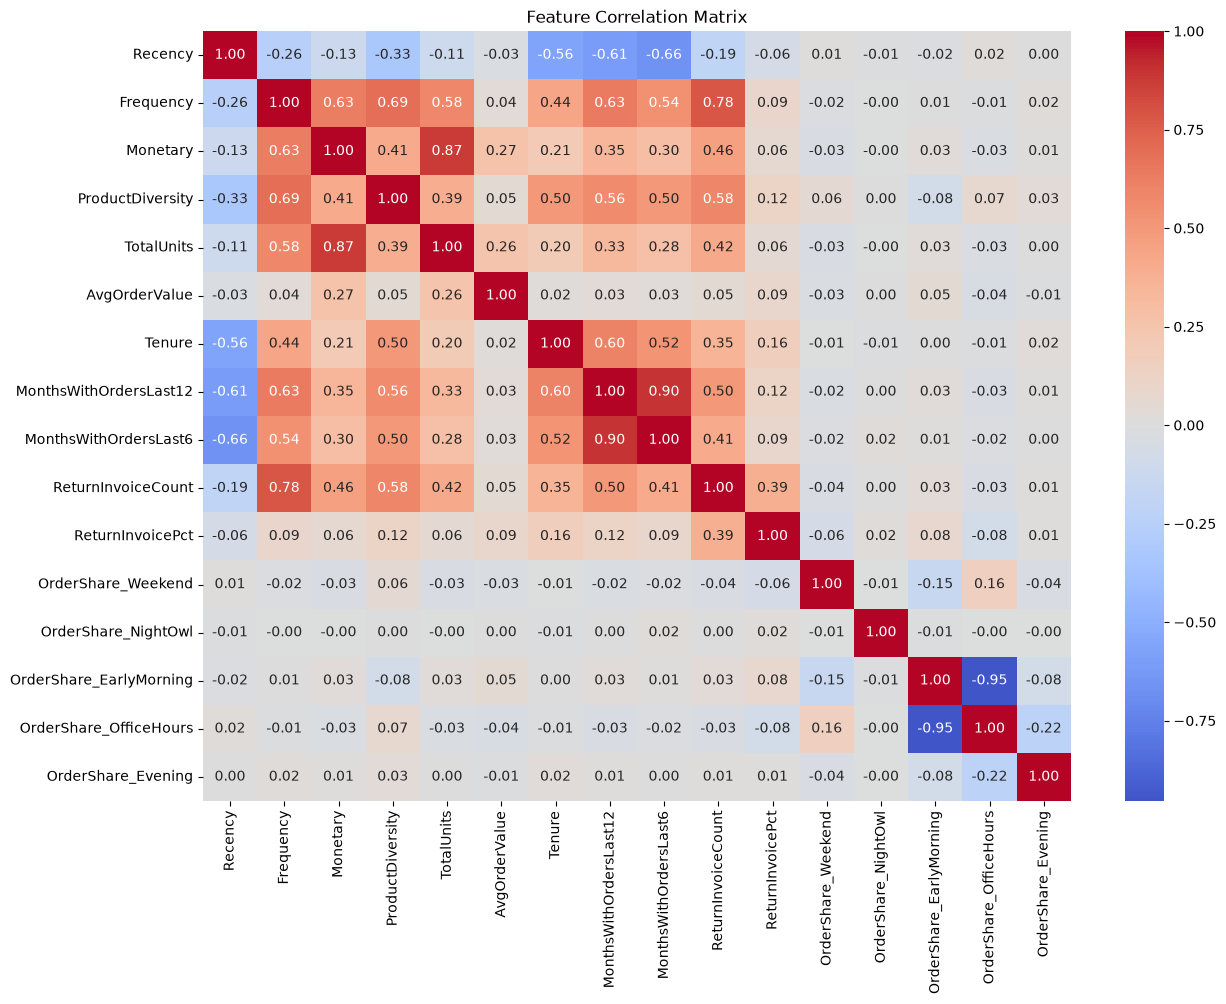

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 10))

sns.heatmap(
    rfm.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Feature Correlation Matrix')
plt.show()

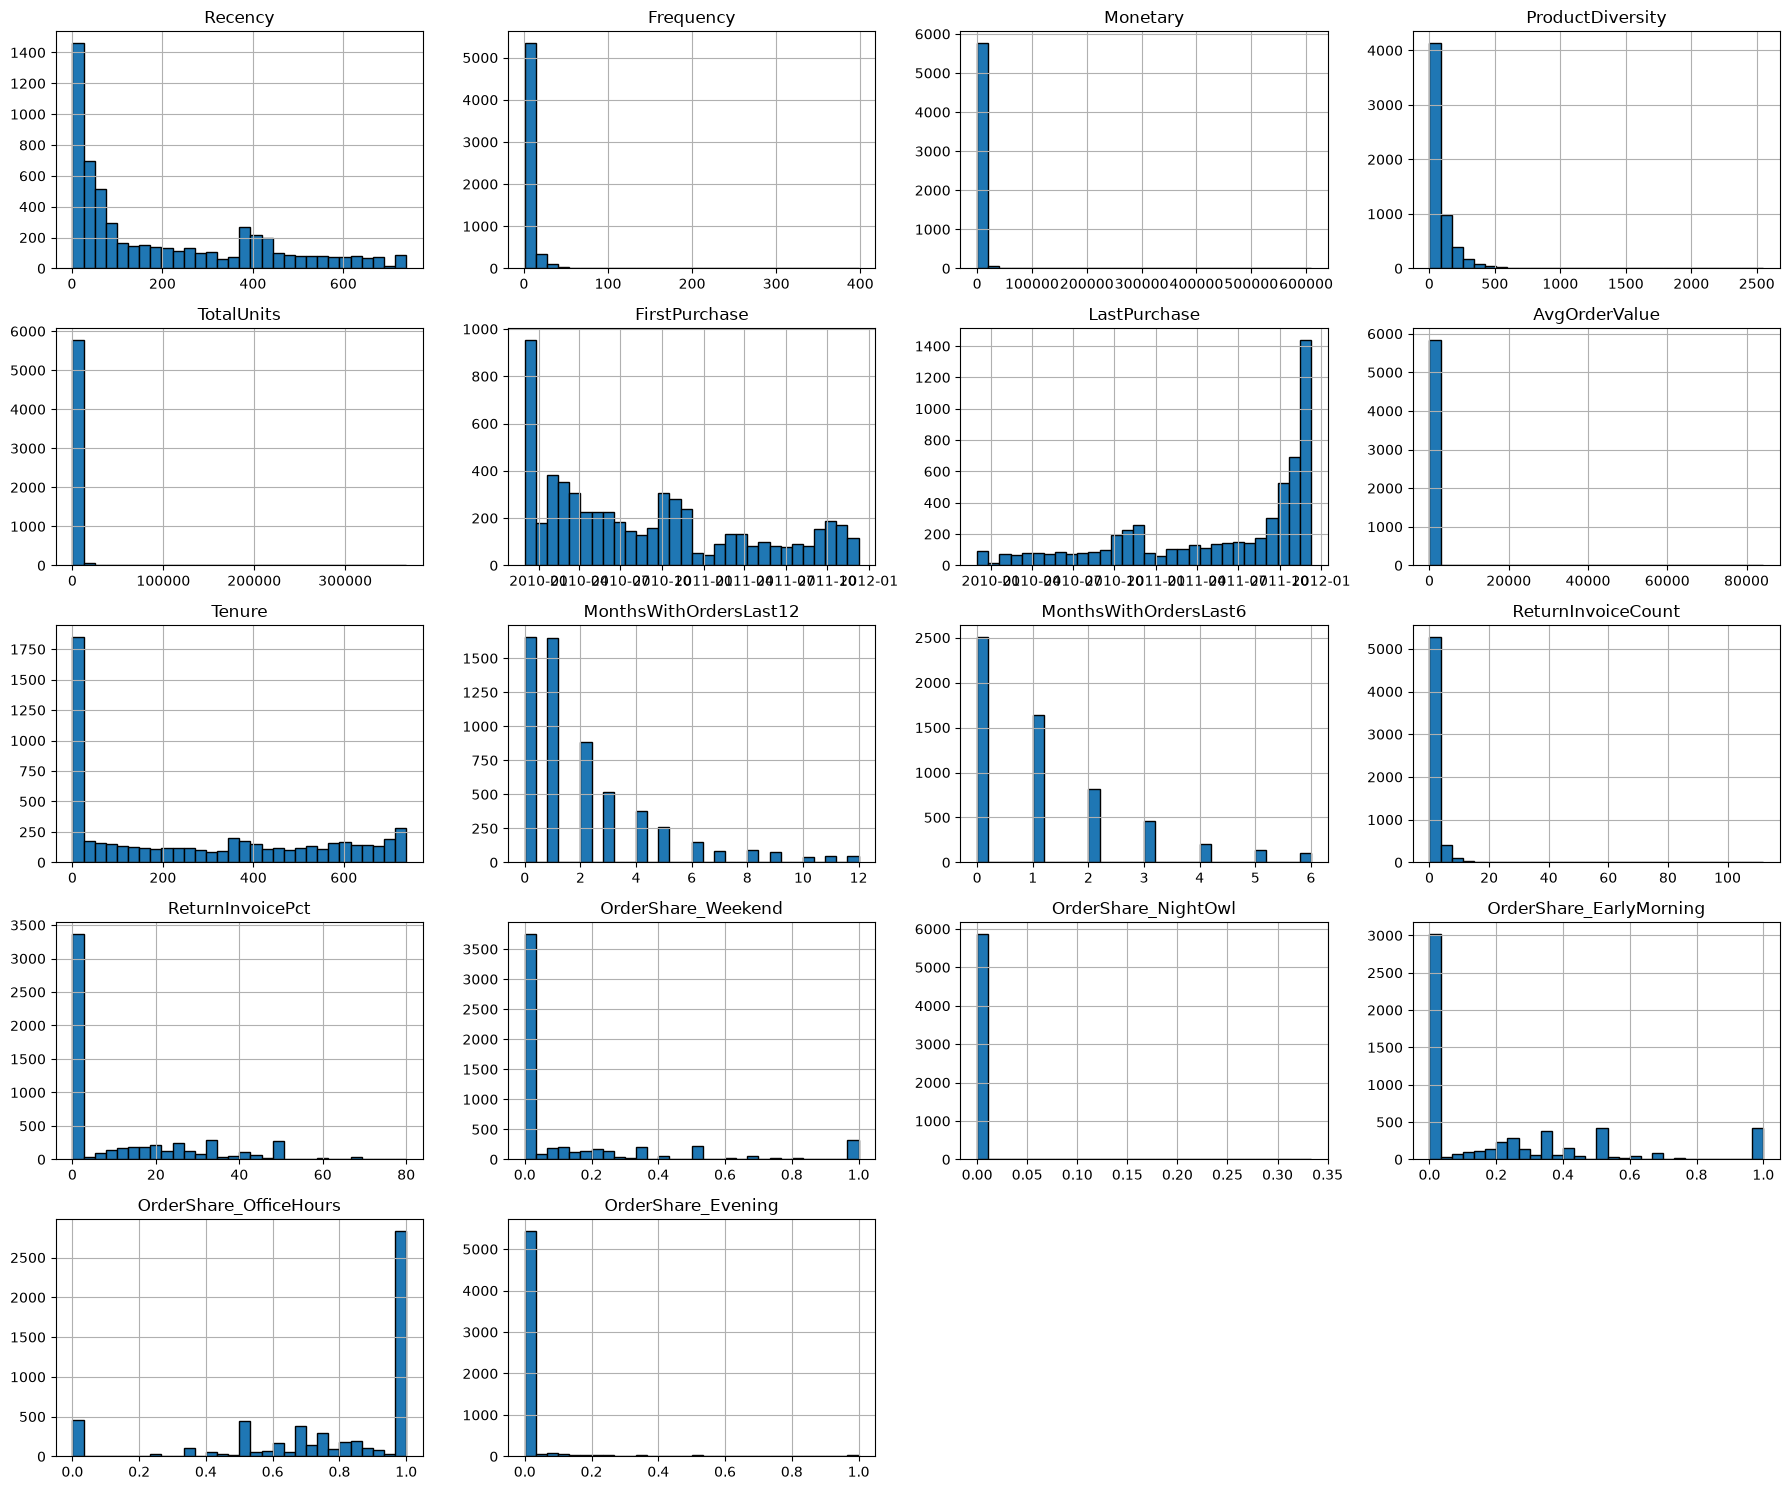

In [ ]:
import matplotlib.pyplot as plt

rfm.hist(
    bins=30,
    figsize=(18, 15),
    edgecolor='black',
    layout=None
)

plt.tight_layout()
plt.show()

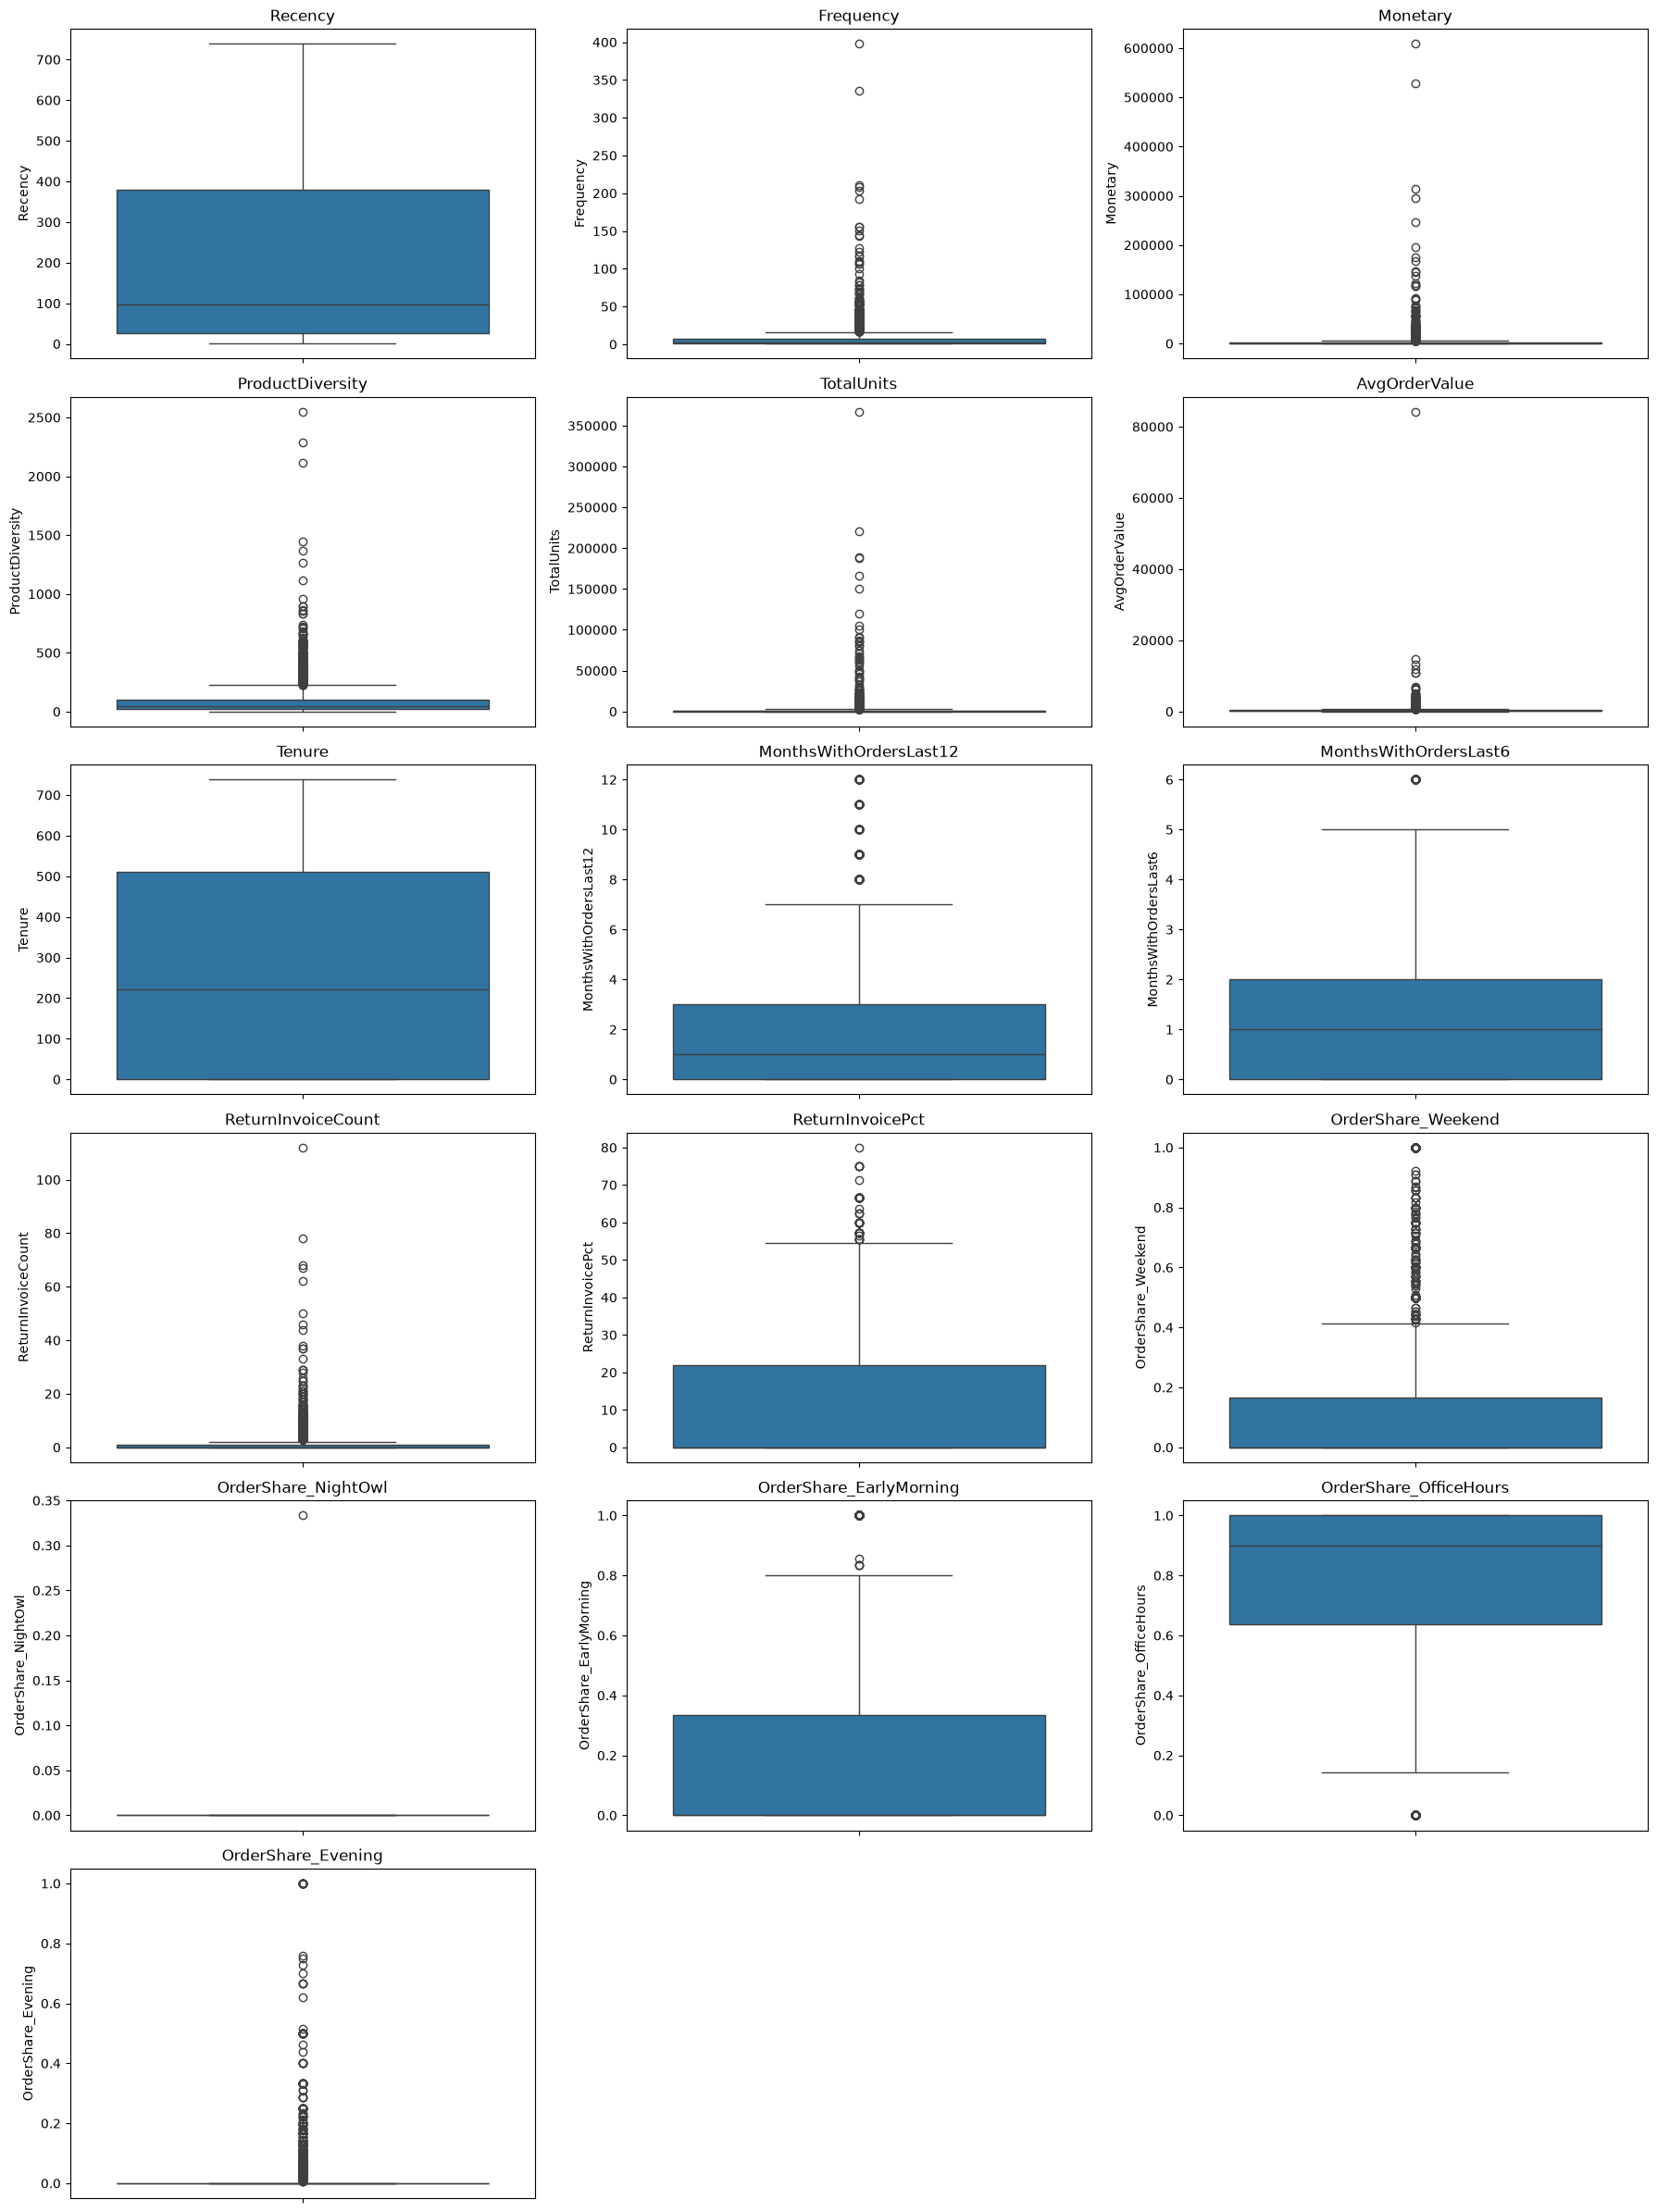

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

numeric_cols = rfm.select_dtypes(include=np.number).columns

n_cols = 3
n_rows = int(np.ceil(len(numeric_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = np.array(axes).flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(data=rfm, y=col, ax=axes[i])
    axes[i].set_title(col)

for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

skewed_cols = [
    'Frequency',
    'Monetary',
    'ProductDiversity',
    'TotalUnits',
    'AvgOrderValue',
    'ReturnInvoiceCount'
]

rfm_log = rfm.copy()

rfm_log[skewed_cols] = np.log1p(rfm_log[skewed_cols])
rfm_log

,Recency,Frequency,Monetary,ProductDiversity,TotalUnits,FirstPurchase,LastPurchase,AvgOrderValue,Tenure,MonthsWithOrdersLast12,MonthsWithOrdersLast6,ReturnInvoiceCount,ReturnInvoicePct,OrderShare_Weekend,OrderShare_NightOwl,OrderShare_EarlyMorning,OrderShare_OfficeHours,OrderShare_Evening
Customer ID,,,,,,,,,,,,,,,,,,
12346.0,326,2.564949,11.258774,3.332205,11.215678,2009-12-14 08:34:00,2011-01-18 10:01:00,8.774010,400,1,0,1.791759,29.411765,0.000000,0.0,0.500000,0.500000,0.000000
12347.0,2,2.197225,8.636632,4.844187,8.097731,2010-10-31 14:20:00,2011-12-07 15:52:00,6.558432,402,6,3,0.000000,0.000000,0.125000,0.0,0.250000,0.750000,0.000000
12348.0,75,1.791759,7.611051,3.258097,7.906547,2010-09-27 14:59:00,2011-09-25 13:13:00,6.003591,362,3,1,0.000000,0.000000,0.200000,0.0,0.400000,0.400000,0.200000
12349.0,19,1.609438,8.396085,4.934474,7.393263,2010-04-29 13:20:00,2011-11-21 09:51:00,7.010468,570,1,1,0.693147,20.000000,0.000000,0.0,0.750000,0.250000,0.000000
12350.0,310,0.693147,5.815324,2.890372,5.288267,2011-02-02 16:01:00,2011-02-02 16:01:00,5.815324,0,1,0,0.000000,0.000000,0.000000,0.0,0.000000,1.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18283.0,4,3.135494,7.914855,5.866468,7.458186,2010-02-19 17:16:00,2011-12-06 12:02:00,4.831454,654,10,5,0.000000,0.000000,0.090909,0.0,0.045455,0.909091,0.045455
18284.0,432,0.693147,6.137036,3.367296,6.204558,2010-10-04 11:33:00,2010-10-04 11:33:00,6.137036,0,0,0,0.693147,50.000000,0.000000,0.0,0.000000,1.000000,0.000000
18285.0,661,0.693147,6.059123,2.564949,4.983607,2010-02-17 10:24:00,2010-02-17 10:24:00,6.059123,0,0,0,0.000000,0.000000,0.000000,0.0,1.000000,0.000000,0.000000


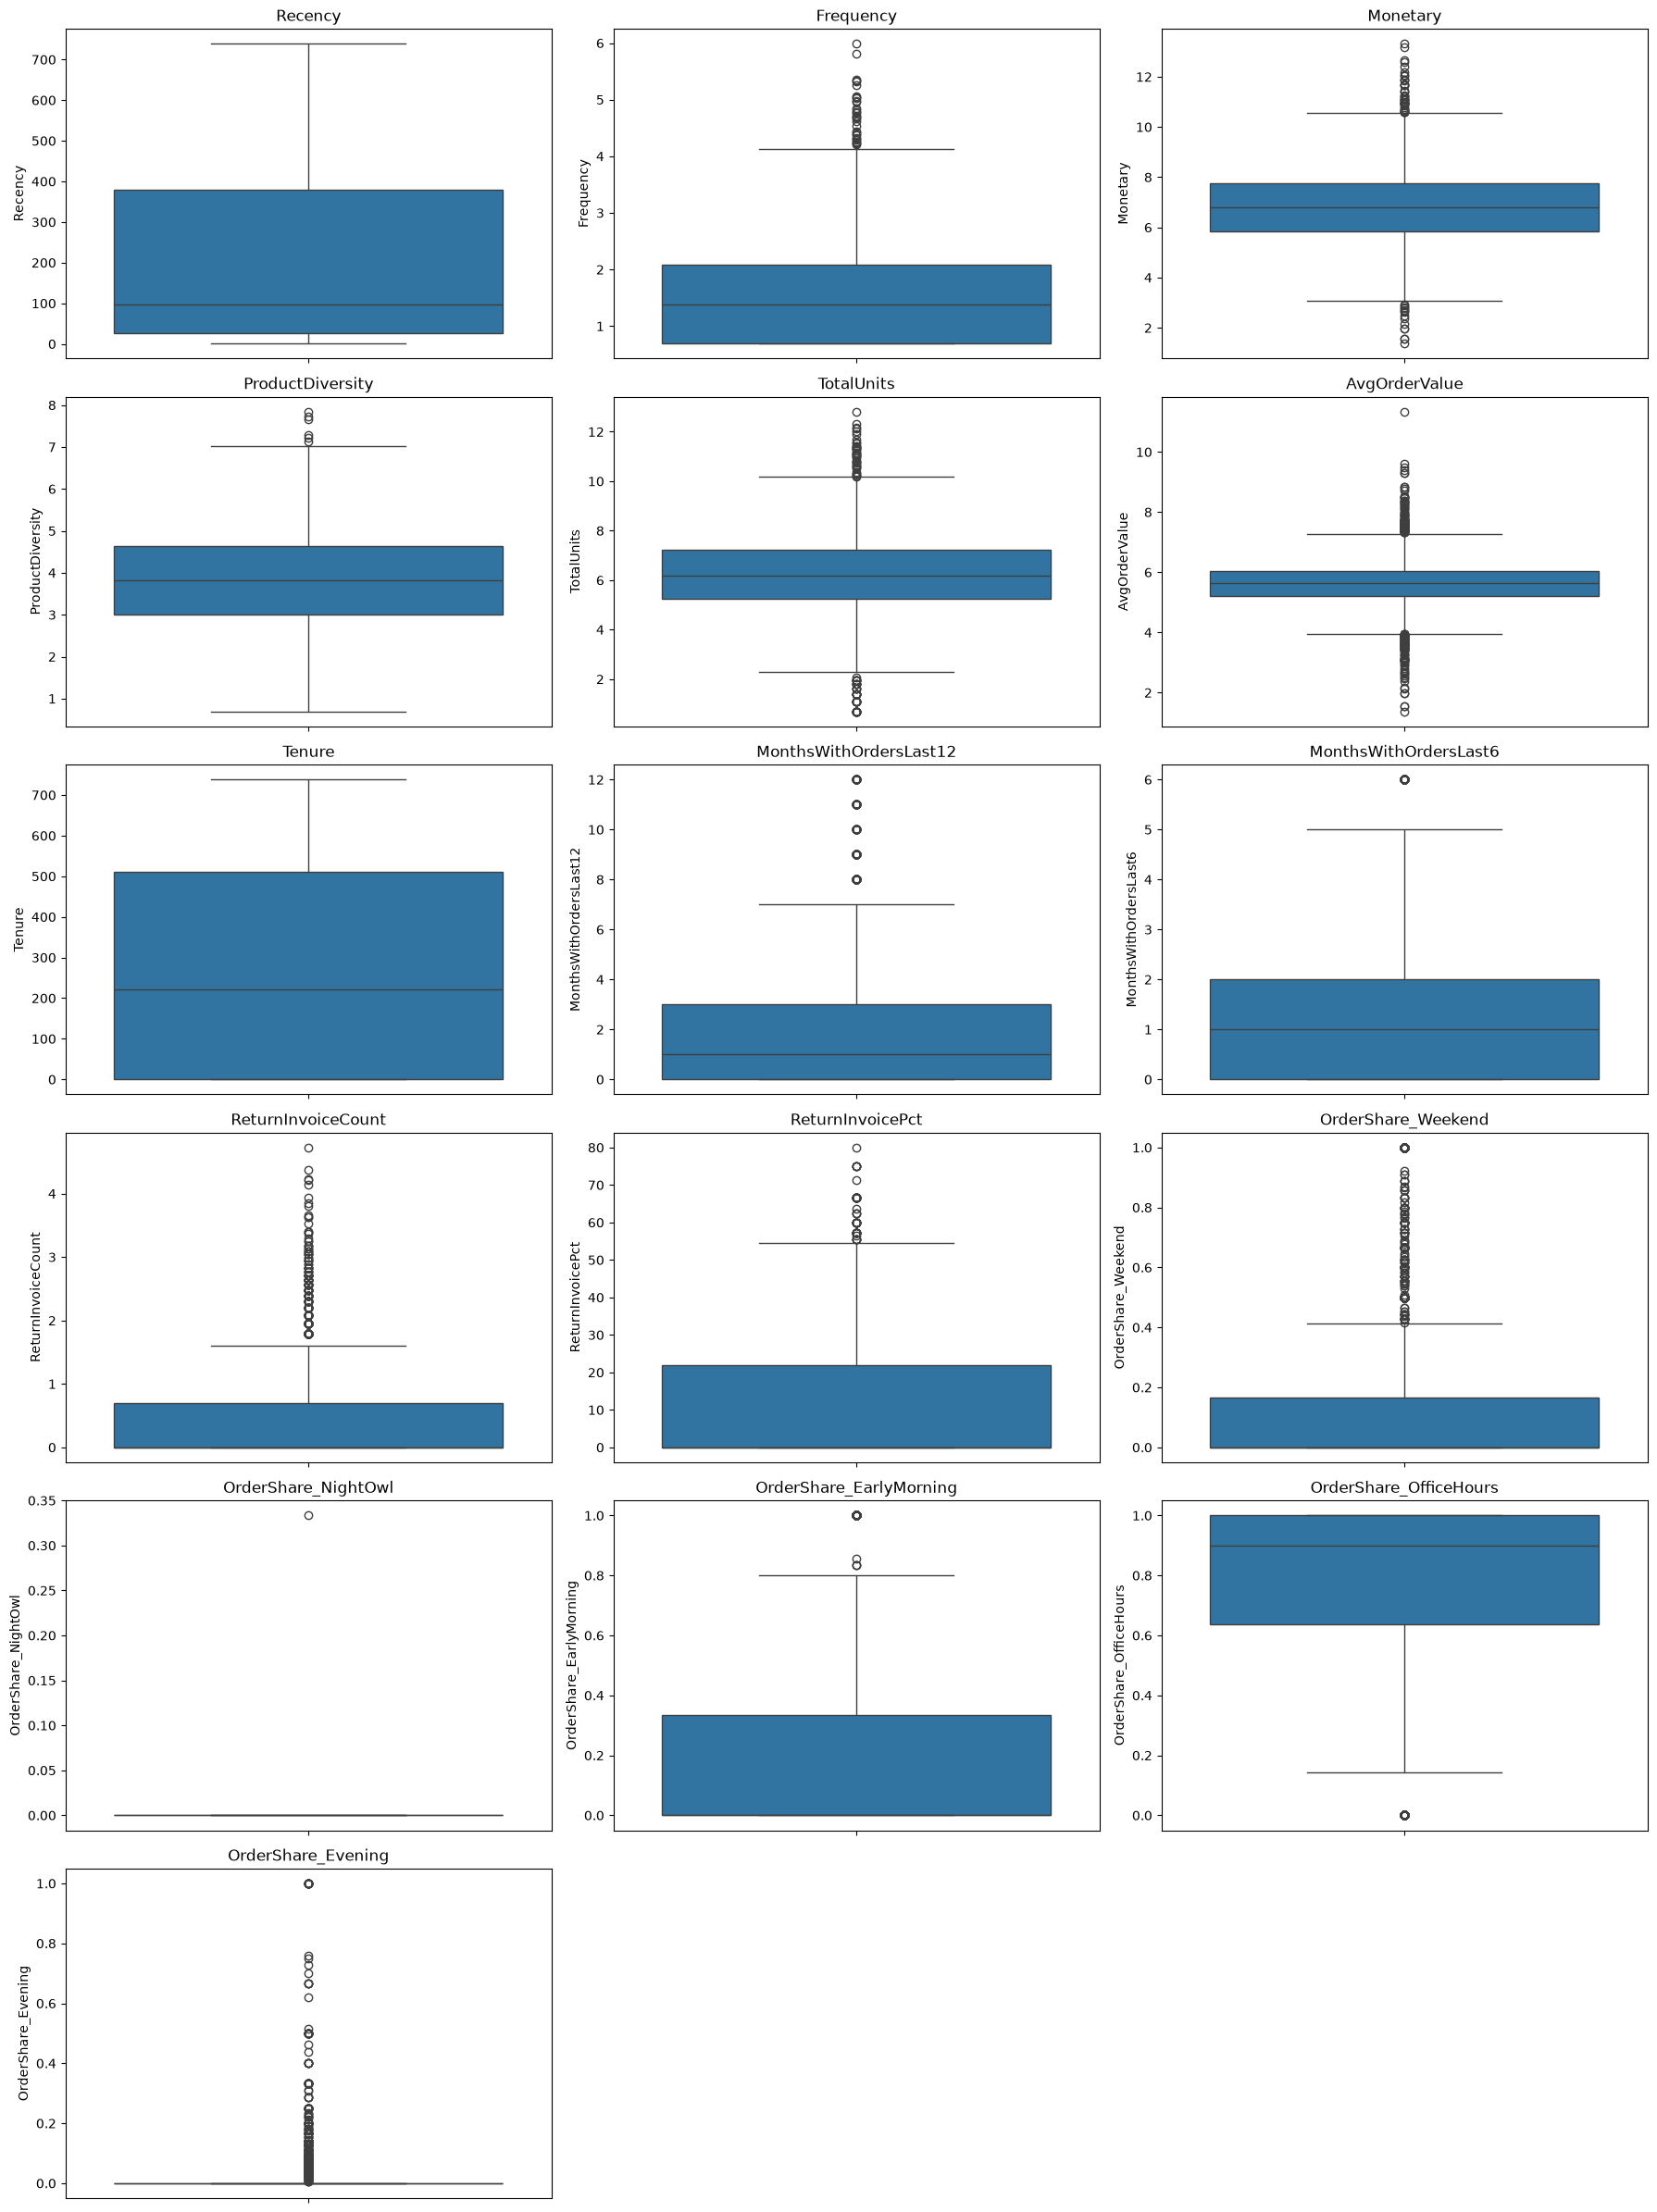

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

numeric_cols = rfm_log.select_dtypes(include=np.number).columns

n_cols = 3
n_rows = int(np.ceil(len(numeric_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = np.array(axes).flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(data=rfm_log, y=col, ax=axes[i])
    axes[i].set_title(col)

for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

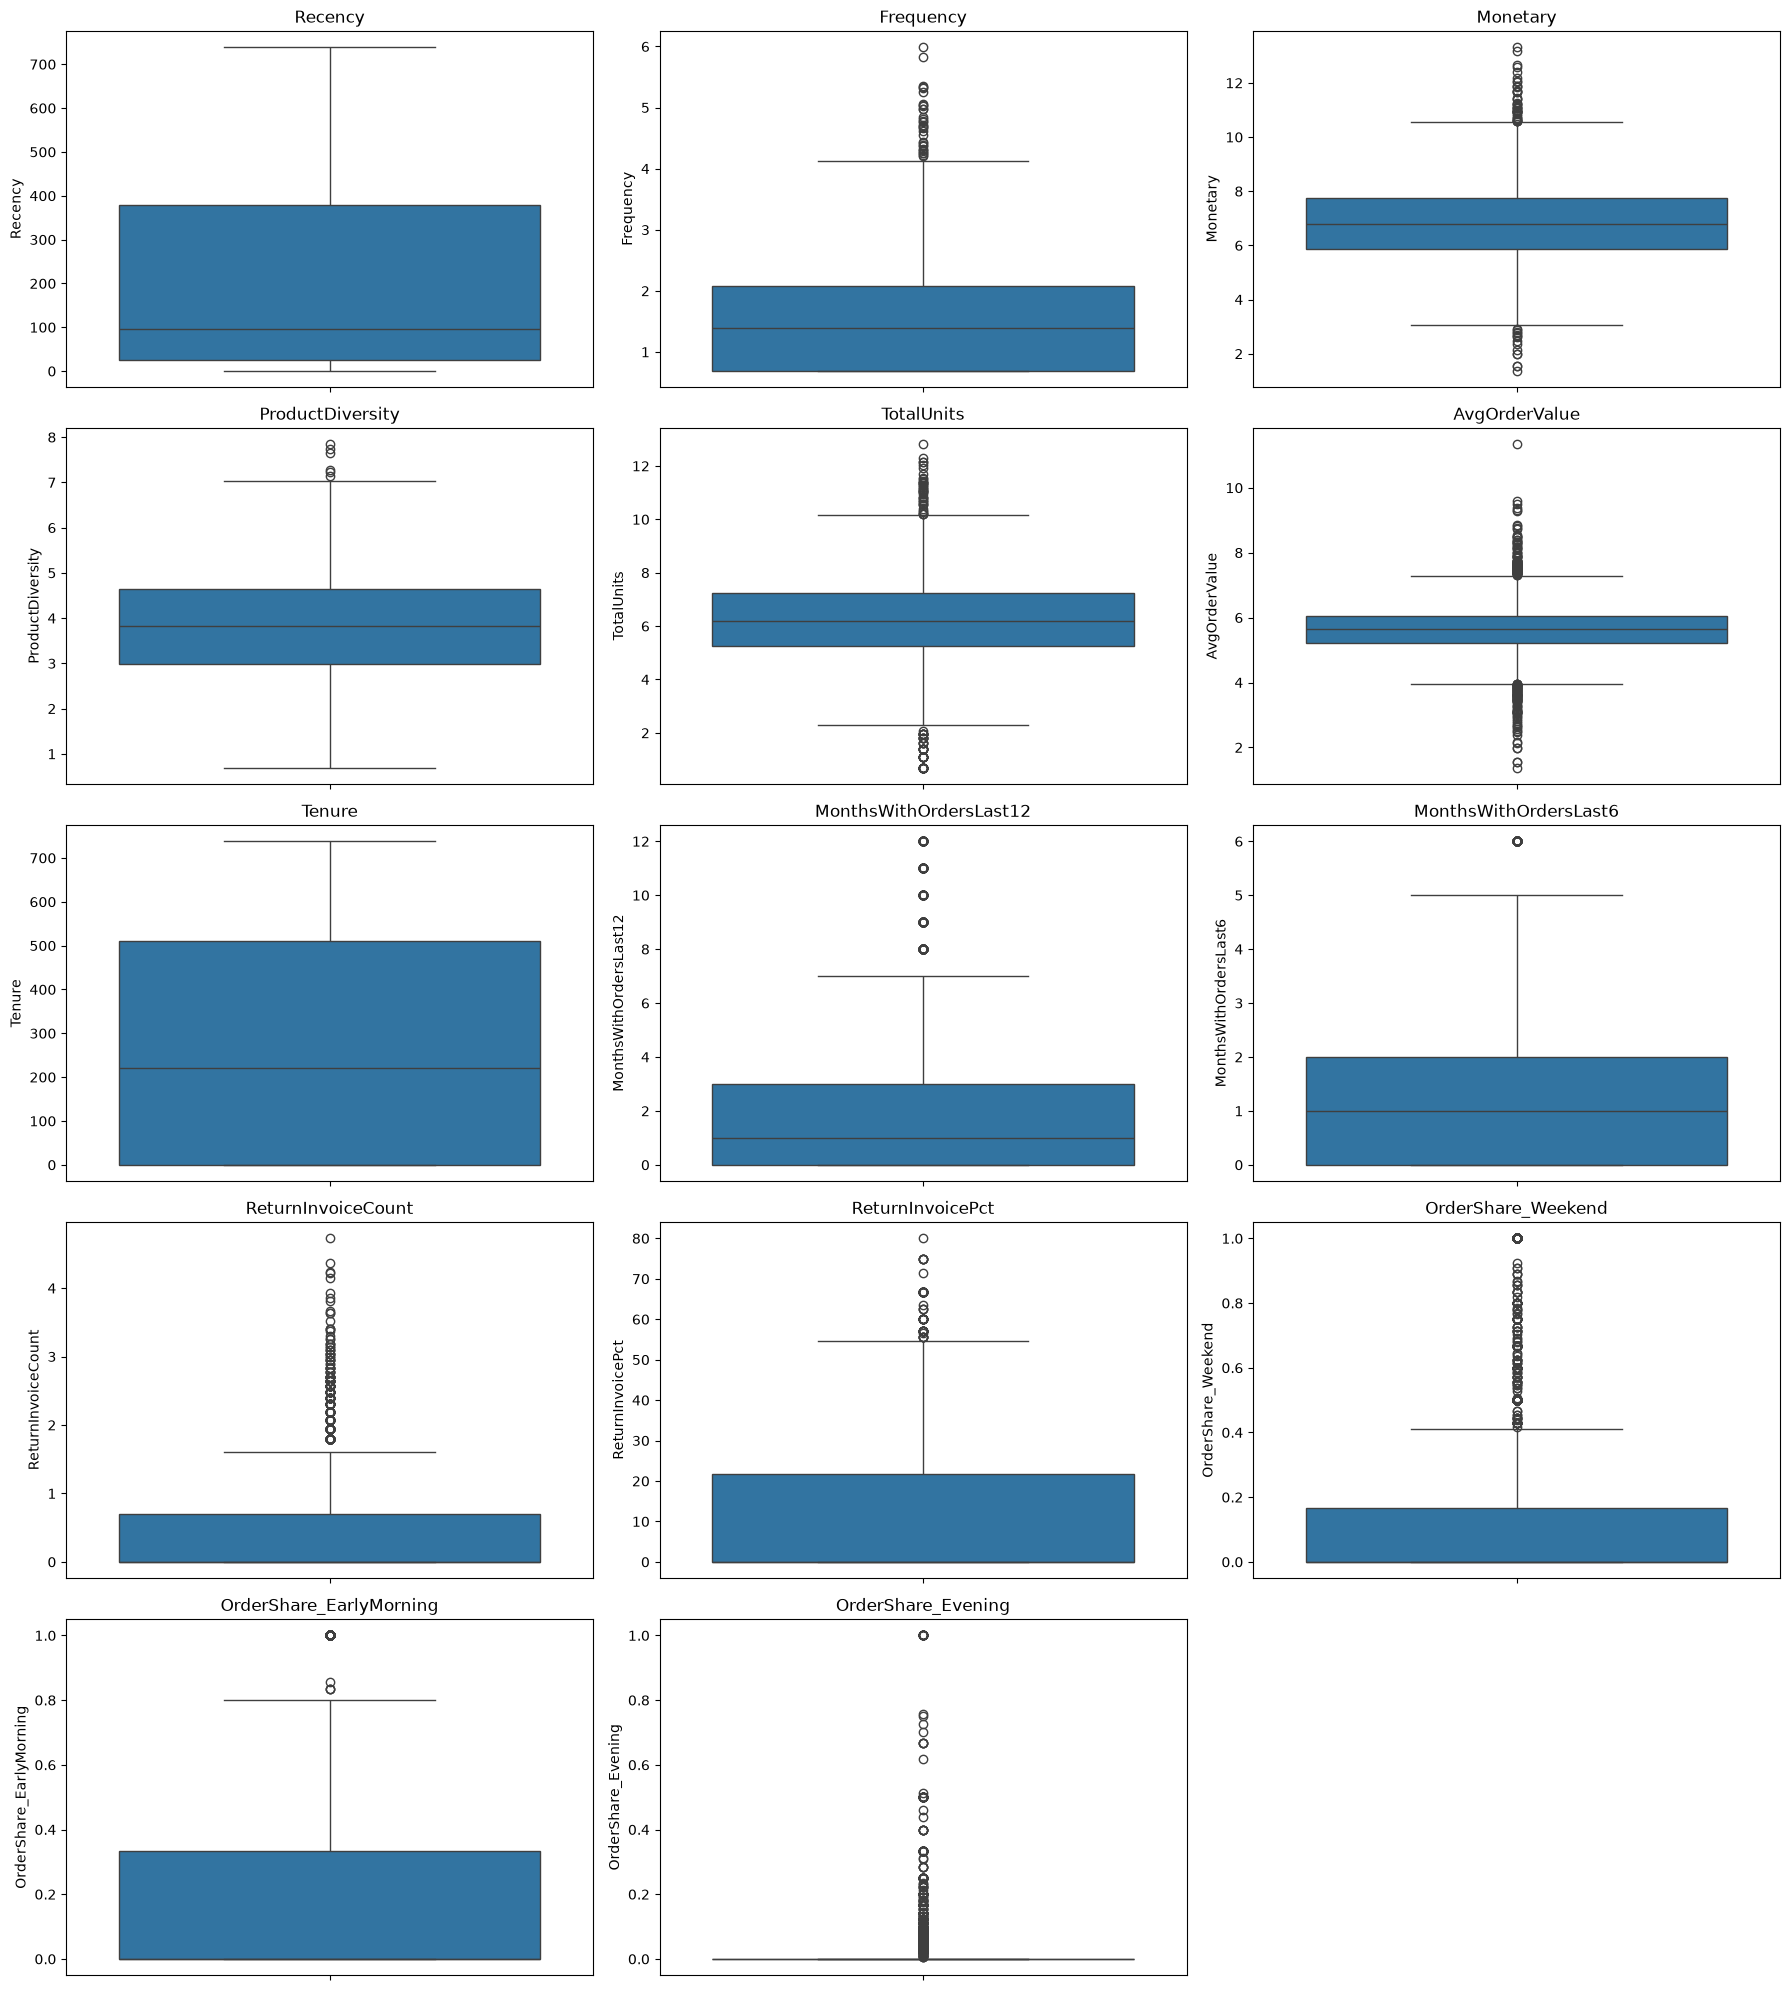

In [ ]:
rfm_log =rfm_log.drop(['FirstPurchase', 'LastPurchase', 'OrderShare_NightOwl','OrderShare_OfficeHours'],axis=1)

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

numeric_cols = rfm_log.select_dtypes(include=np.number).columns

n_cols = 3
n_rows = int(np.ceil(len(numeric_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = np.array(axes).flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(data=rfm_log, y=col, ax=axes[i])
    axes[i].set_title(col)

for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler

# Keep all numeric features; Customer ID is the index and is not a feature.
# Raw purchase timestamps are excluded because they are not numeric features.
rfm_features = rfm_log.select_dtypes(include="number").copy()

if rfm_features.isna().any().any():
    raise ValueError("rfm_log contains missing numeric feature values; handle them before scaling.")

scaler = StandardScaler()
rfm_scaled = pd.DataFrame(
    scaler.fit_transform(rfm_features),
    index=rfm_features.index,
    columns=rfm_features.columns,
)

print(f"Scaled {rfm_scaled.shape[1]} features for {rfm_scaled.shape[0]} customers.")
display(rfm_scaled.head())

Scaled 14 features for 5878 customers.


,Recency,Frequency,Monetary,ProductDiversity,TotalUnits,AvgOrderValue,Tenure,MonthsWithOrdersLast12,MonthsWithOrdersLast6,ReturnInvoiceCount,ReturnInvoicePct,OrderShare_Weekend,OrderShare_EarlyMorning,OrderShare_Evening
Customer ID,,,,,,,,,,,,,,
12346.0,0.595584,1.254496,3.186625,-0.350753,3.292228,4.264242,0.490667,-0.436735,-0.820094,1.853852,1.067154,-0.529718,0.992626,-0.19737
12347.0,-0.952279,0.800166,1.297127,0.889667,1.241488,1.253001,0.498395,1.603582,1.308794,-0.721870,-0.710259,-0.055875,0.133696,-0.19737
12348.0,-0.603532,0.299207,0.558100,-0.411550,1.115743,0.498904,0.343827,0.379392,-0.110465,-0.721870,-0.710259,0.228431,0.649054,2.04428
12349.0,-0.871064,0.073946,1.123790,0.963738,0.778145,1.867373,1.147582,-0.436735,-0.110465,0.274555,0.498382,-0.529718,1.851556,-0.19737
12350.0,0.519146,-1.058146,-0.735888,-0.713229,-0.606355,0.243026,-1.055014,-0.436735,-0.820094,-0.721870,-0.710259,-0.529718,-0.725235,-0.19737


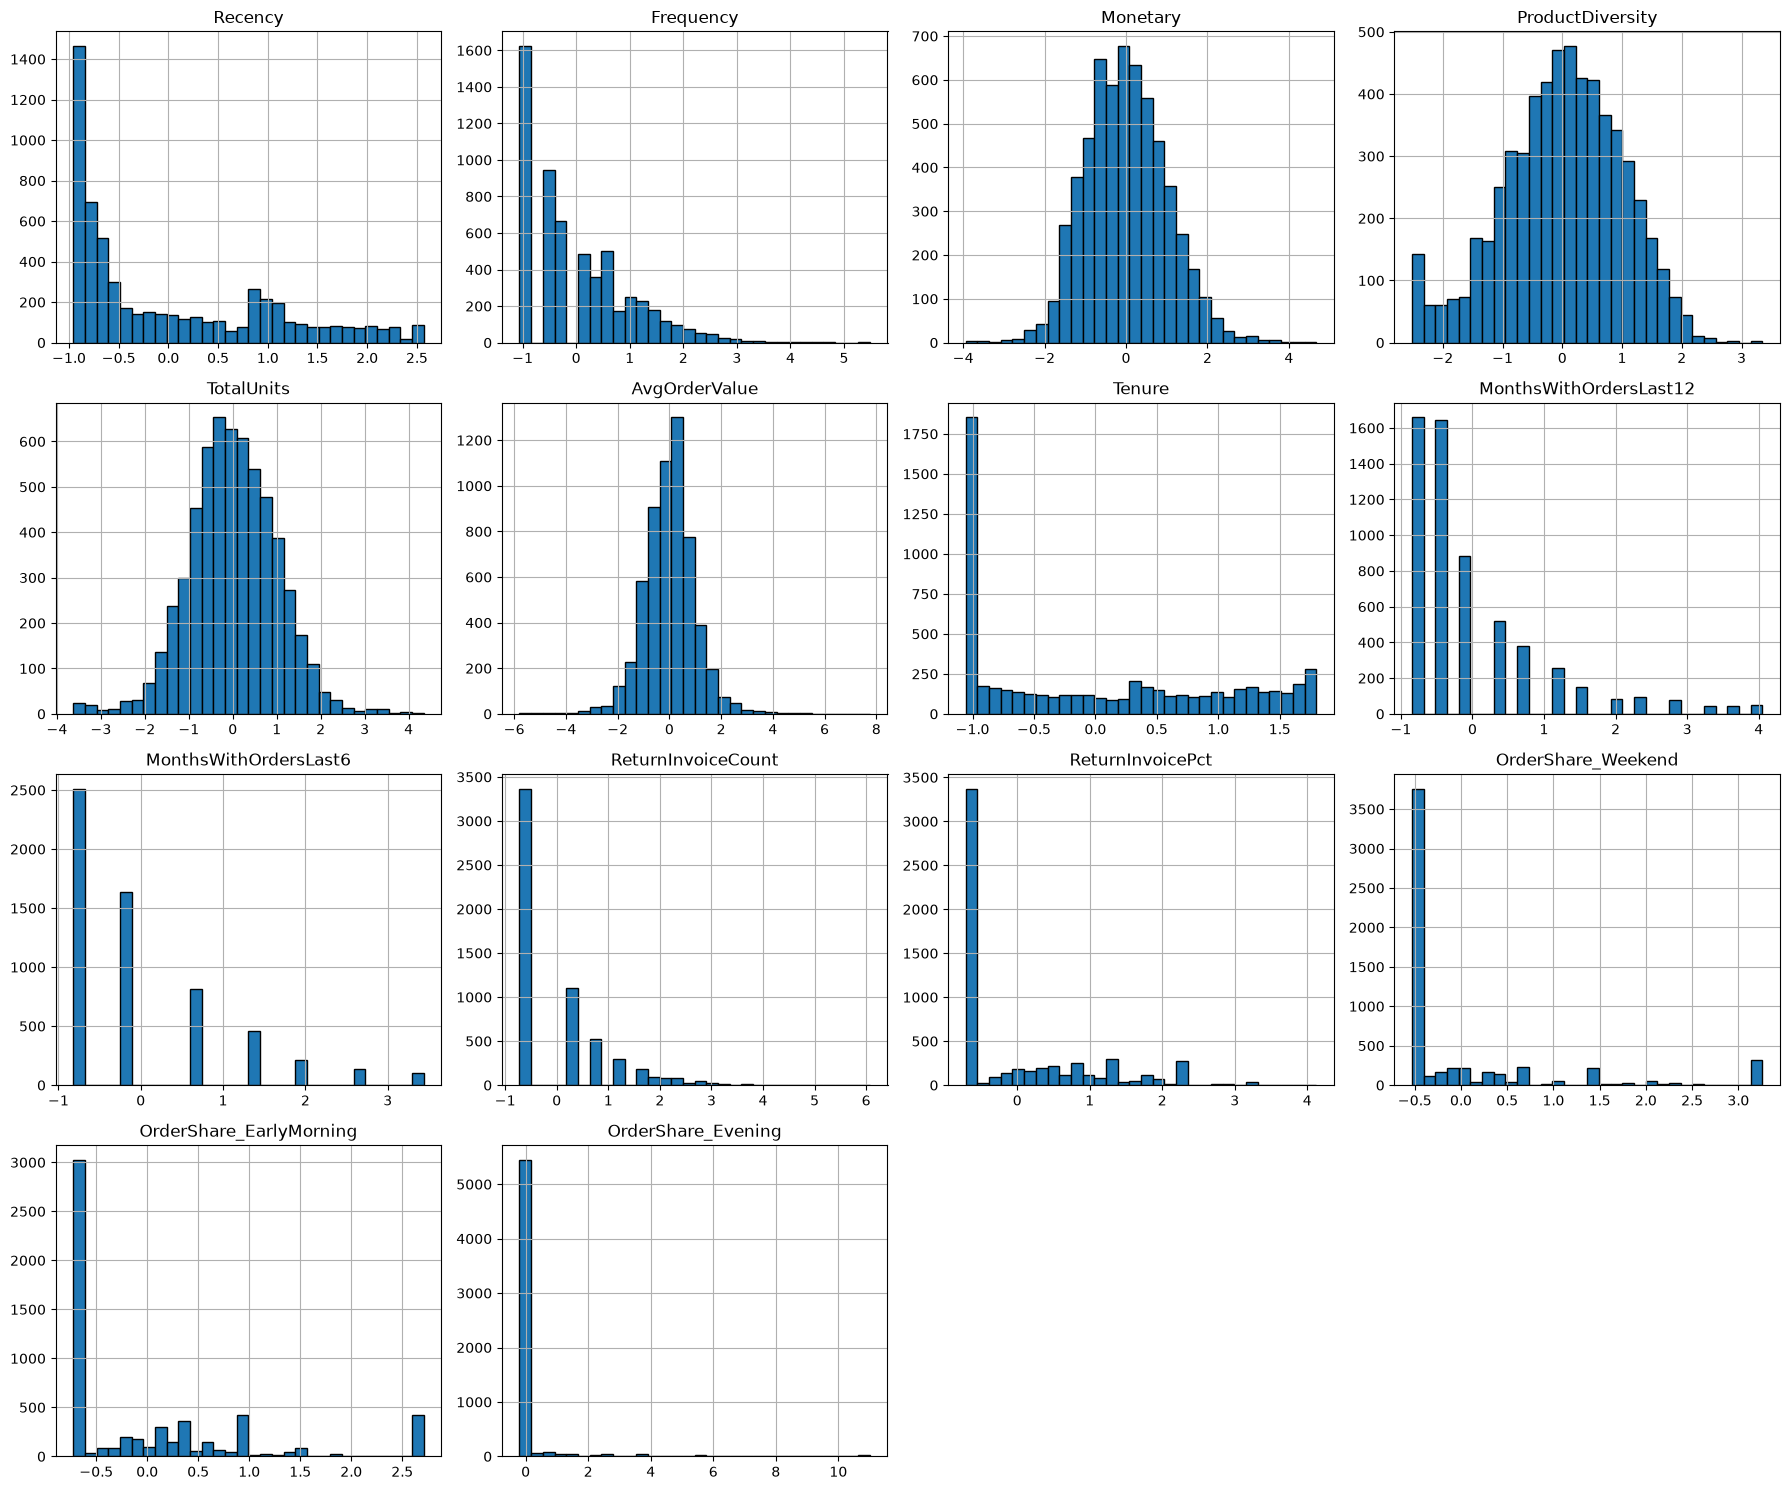

In [ ]:
import matplotlib.pyplot as plt

rfm_scaled.hist(
    bins=30,
    figsize=(18, 15),
    edgecolor='black',
    layout=None
)

plt.tight_layout()
plt.show()

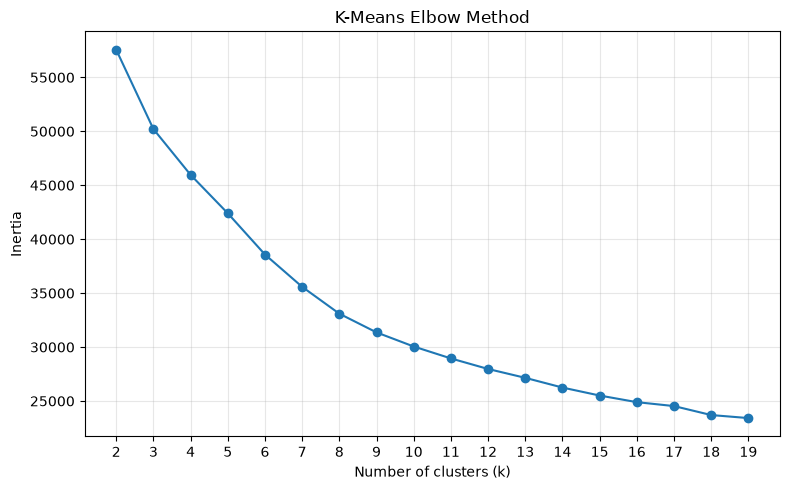

In [ ]:
# Compare K-Means inertia across candidate cluster counts before choosing k.
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

k_values = range(2, 20)
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(rfm_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xticks(list(k_values))
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

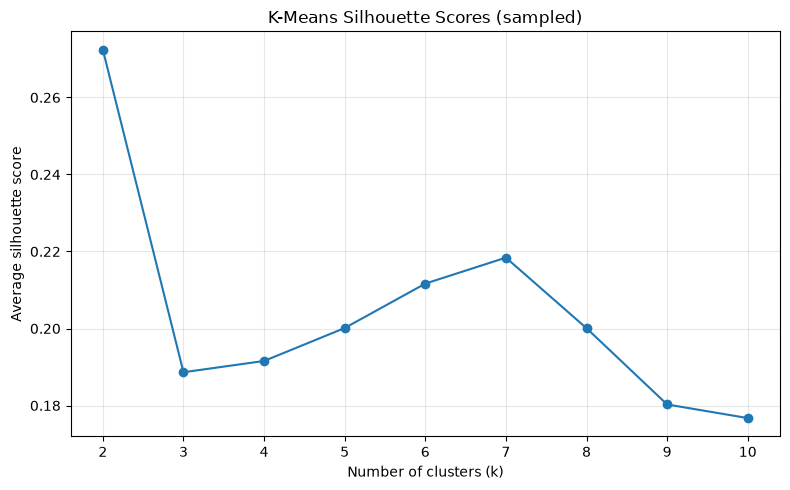

Scores: {2: 0.2723965637787489, 3: 0.18864234467160326, 4: 0.19156863803042387, 5: 0.2001230972397419, 6: 0.21166196047966207, 7: 0.21840707322723268, 8: 0.2000758057475875, 9: 0.18027102045745574, 10: 0.17673568931363218}


In [ ]:
# Compare candidate k values with silhouette scores (higher is better).
# Sampling keeps this pairwise-distance calculation manageable for thousands of customers.
from sklearn.metrics import silhouette_score

silhouette_k_values = range(2, 11)
silhouette_scores = []

for k in silhouette_k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(rfm_scaled)
    score = silhouette_score(
        rfm_scaled,
        labels,
        sample_size=min(2000, len(rfm_scaled)),
        random_state=42,
    )
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(list(silhouette_k_values), silhouette_scores, marker="o")
plt.xticks(list(silhouette_k_values))
plt.xlabel("Number of clusters (k)")
plt.ylabel("Average silhouette score")
plt.title("K-Means Silhouette Scores (sampled)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Scores:", dict(zip(silhouette_k_values, silhouette_scores)))

In [ ]:
# Compare with Ward agglomerative clustering using the same scaled features and k=2.
from sklearn.cluster import AgglomerativeClustering

agglomerative_2 = AgglomerativeClustering(n_clusters=2, linkage="ward")
rfm["AgglomerativeCluster"] = agglomerative_2.fit_predict(rfm_scaled)

print("Customer counts per agglomerative cluster:")
display(
    rfm["AgglomerativeCluster"]
    .value_counts()
    .sort_index()
    .rename("CustomerCount")
    .to_frame()
)

agglomerative_profile = (
    rfm.drop(columns=["Cluster", "AgglomerativeCluster"], errors="ignore")
    .select_dtypes(include="number")
    .groupby(rfm["AgglomerativeCluster"])
    .mean()
    .round(2)
)
display(agglomerative_profile)

Customer counts per agglomerative cluster:


,CustomerCount
AgglomerativeCluster,
0,4519
1,1359


,Recency,Frequency,Monetary,ProductDiversity,TotalUnits,AvgOrderValue,Tenure,MonthsWithOrdersLast12,MonthsWithOrdersLast6,ReturnInvoiceCount,ReturnInvoicePct,OrderShare_Weekend,OrderShare_NightOwl,OrderShare_EarlyMorning,OrderShare_OfficeHours,OrderShare_Evening
AgglomerativeCluster,,,,,,,,,,,,,,,,
0,251.30,2.98,1081.68,49.67,699.37,368.12,183.64,1.10,0.65,0.54,10.11,0.14,0.0,0.21,0.77,0.02
1,35.17,17.28,9459.38,189.45,5552.39,470.22,570.26,5.29,2.85,3.97,17.21,0.13,0.0,0.23,0.76,0.01


In [ ]:
# Compare K-Means cluster sizes and average original feature values for k=2, 3, and 4.
from sklearn.cluster import KMeans

profile_features = rfm.select_dtypes(include="number").drop(columns=["Cluster", "AgglomerativeCluster"], errors="ignore").loc[rfm_scaled.index]
cluster_comparisons = []

for n_clusters in (2, 3, 4,7):
    model = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    cluster_labels = pd.Series(model.fit_predict(rfm_scaled), index=rfm_scaled.index, name="Cluster")
    cluster_means = profile_features.groupby(cluster_labels).mean()
    customer_counts = cluster_labels.value_counts().rename("CustomerCount")
    comparison = cluster_means.join(customer_counts)
    comparison.insert(0, "CustomerCount", comparison.pop("CustomerCount"))
    comparison["K"] = n_clusters
    comparison.index.name = "Cluster"
    cluster_comparisons.append(comparison.reset_index().set_index(["K", "Cluster"]))

kmeans_comparison = pd.concat(cluster_comparisons).sort_index()
display(kmeans_comparison.round(2))


CustomerCount  Recency  Frequency  Monetary  ProductDiversity  \
K Cluster                                                                  
2 0                 2250    57.05      12.94   6881.10            158.13   
  1                 3628   290.81       2.16    623.20             34.77   
3 0                 2353   353.68       1.55    357.97             21.61   
  1                  994    29.41      21.29  12405.84            222.61   
  2                 2531   127.22       4.80   1805.50             82.89   
4 0                 1896    95.02       5.09   1769.01             89.07   
  1                 1990   353.41       1.49    331.38             21.47   
  2                  998   270.71       3.29   1404.38             49.92   
  3                  994    30.01      21.20  12402.79            221.84   
7 0                  526   297.62       1.60    472.79             19.54   
  1                 1347   349.50       1.56    338.19             22.82   
  2                  909   252.26       3.71   1886.68             56.66   
  3                  906    28.26      22.30  13039.93            229.25   
  4                 1643    82.69       5.67   1961.78             96.54   
  5                   68   283.56       3.12    772.48             56.38   
  6                  479   304.91       1.91    489.16             40.21   

           TotalUnits  AvgOrderValue  Tenure  MonthsWithOrdersLast12  \
K Cluster                                                              
2 0           4184.17         521.22  509.11                    4.15   
  1            356.06         311.41  126.61                    0.78   
3 0            196.71         253.50   52.86                    0.51   
  1           7292.49         591.48  595.12                    6.22   
  2           1183.16         441.78  351.21                    1.89   
4 0           1135.10         400.90  376.69                    2.15   
  1            190.62         242.28   47.06                    0.51   
  2            928.97         470.12  205.82                    0.96   
  3           7291.31         594.71  595.14                    6.15   
7 0            272.69         308.37   75.93                    0.71   
  1            199.20         243.77   49.43                    0.52   
  2           1227.86         619.59  239.43                    1.09   
  3           7687.39         518.05  598.25                    6.37   
  4           1248.57         384.12  415.00                    2.39   
  5            463.78         247.25  150.71                    1.09   
  6            272.58         274.54   97.18                    0.69   

           MonthsWithOrdersLast6  ReturnInvoiceCount  ReturnInvoicePct  \
K Cluster                                                                
2 0                         2.29                2.98             17.36   
  1                         0.45                0.31              8.27   
3 0                         0.28                0.19              6.55   
  1                         3.28                5.17             19.36   
  2                         1.14                0.88             13.61   
4 0                         1.33                0.35              4.74   
  1                         0.27                0.02              0.74   
  2                         0.50                1.94             38.87   
  3                         3.24                5.23             19.94   
7 0                         0.39                0.12              4.88   
  1                         0.29                0.06              1.82   
  2                         0.55                2.11             37.65   
  3                         3.36                5.53             20.13   
  4                         1.46                0.40              5.26   
  5                         0.65                0.46             10.72   
  6                         0.46                0.14              4.65   

           O

In [ ]:
# DBSCAN does not take a target k; compare min_samples values and data-derived eps candidates.
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

min_samples_values = (2, 3, 7)
eps_quantiles = (0.90, 0.95)
dbscan_rows = []
dbscan_labels = {}

for min_samples in min_samples_values:
    neighbors = NearestNeighbors(n_neighbors=min_samples).fit(rfm_scaled)
    neighbor_distances, _ = neighbors.kneighbors(rfm_scaled)
    kth_neighbor_distances = neighbor_distances[:, -1]

    for quantile in eps_quantiles:
        eps = float(np.quantile(kth_neighbor_distances, quantile))
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(rfm_scaled)
        n_clusters = len(set(labels) - {-1})
        noise_count = int((labels == -1).sum())
        dbscan_labels[(min_samples, quantile)] = pd.Series(labels, index=rfm_scaled.index)
        dbscan_rows.append({
            "min_samples": min_samples,
            "eps_quantile": quantile,
            "eps": eps,
            "clusters_found": n_clusters,
            "noise_customers": noise_count,
            "noise_pct": noise_count / len(labels) * 100,
        })

dbscan_comparison = pd.DataFrame(dbscan_rows)
display(dbscan_comparison.round({"eps": 3, "noise_pct": 1}))


,min_samples,eps_quantile,eps,clusters_found,noise_customers,noise_pct
0,2,0.90,1.344,73,588,10.0
1,2,0.95,1.573,41,294,5.0
2,3,0.90,1.503,18,437,7.4
3,3,0.95,1.769,7,205,3.5
4,7,0.90,1.789,4,296,5.0
5,7,0.95,2.101,4,130,2.2


In [ ]:
from sklearn.metrics import silhouette_score

results = []

for (min_samples, quantile), labels in dbscan_labels.items():

    mask = labels != -1
    n_clusters = len(set(labels[mask]))

    if n_clusters >= 2 and mask.sum() > n_clusters:
        score = silhouette_score(
            rfm_scaled.loc[mask],
            labels.loc[mask]
        )
    else:
        score = np.nan

    results.append({
        'min_samples': min_samples,
        'eps_quantile': quantile,
        'n_clusters': n_clusters,
        'noise_pct': (~mask).mean() * 100,
        'silhouette': score
    })

pd.DataFrame(results)

,min_samples,eps_quantile,n_clusters,noise_pct,silhouette
0,2,0.90,73,10.003403,-0.378352
1,2,0.95,41,5.001701,-0.293079
2,3,0.90,18,7.434502,-0.185029
3,3,0.95,7,3.487581,0.180026
4,7,0.90,4,5.035726,0.214517
5,7,0.95,4,2.211637,0.213045


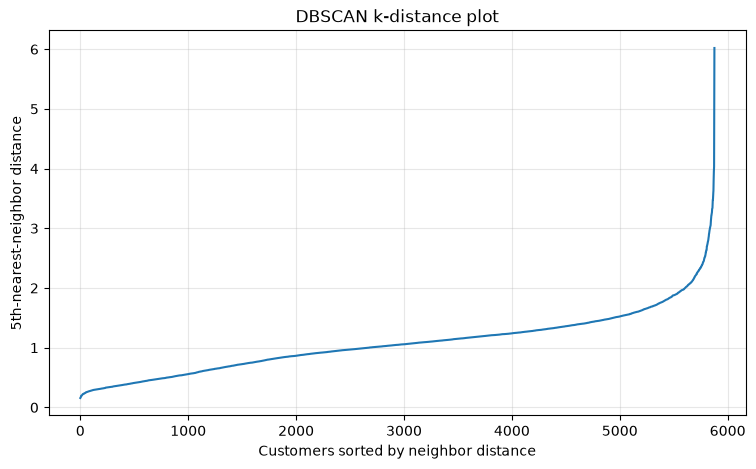

In [ ]:
import matplotlib.pyplot as plt

min_samples = 5

neighbors = NearestNeighbors(
    n_neighbors=min_samples
).fit(rfm_scaled)

distances, _ = neighbors.kneighbors(rfm_scaled)

k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(k_distances)
plt.xlabel("Customers sorted by neighbor distance")
plt.ylabel("5th-nearest-neighbor distance")
plt.title("DBSCAN k-distance plot")
plt.grid(alpha=0.3)
plt.show()

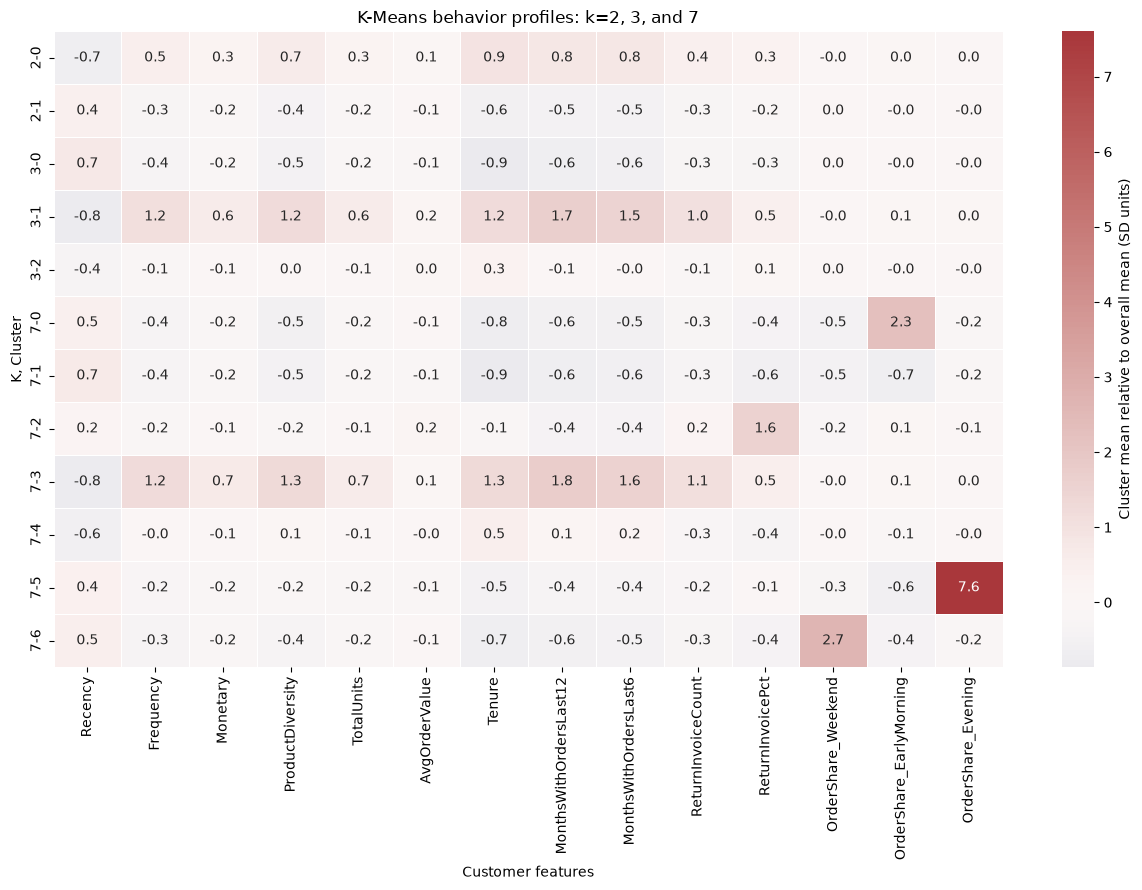

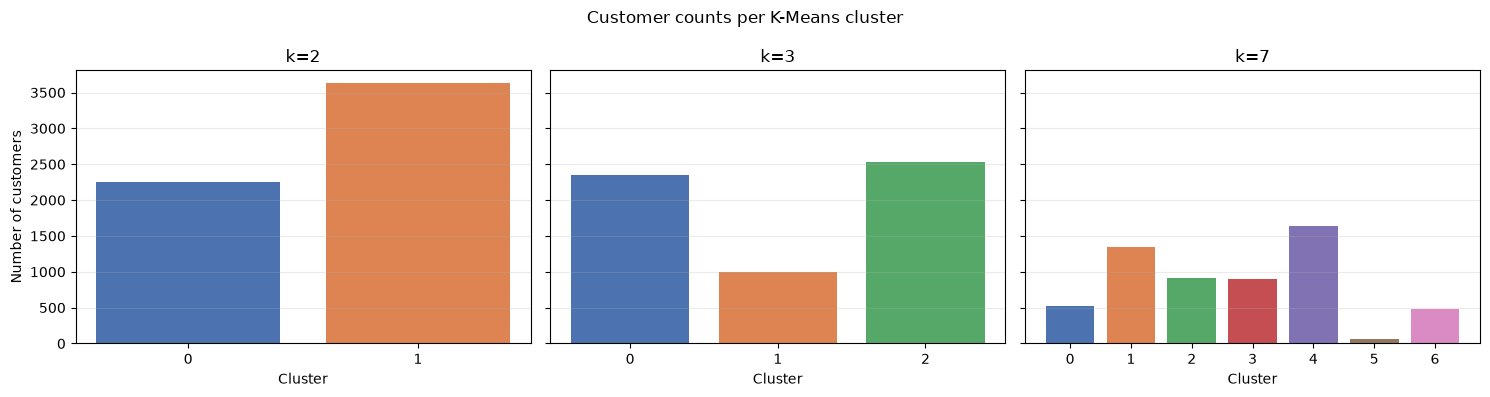

Cluster sizes:


CustomerCount
K Cluster               
2 0                 2250
  1                 3628
3 0                 2353
  1                  994
  2                 2531
7 0                  526
  1                 1347
  2                  909
  3                  906
  4                 1643
  5                   68
  6                  479

Median feature values (original units; useful for skewed features):


Recency  Frequency  Monetary  ProductDiversity  TotalUnits  \
K Cluster                                                               
2 0           29.0        8.0   2999.10             118.0      1735.0   
  1          281.0        2.0    428.40              25.0       241.5   
3 0          387.0        1.0    293.35              17.0       152.0   
  1           16.0       15.0   5745.06             177.0      3348.5   
  2           66.0        4.0   1299.49              64.0       748.0   
7 0          281.0        1.0    353.14              16.0       190.0   
  1          382.0        1.0    254.00              17.0       145.0   
  2          218.0        3.0   1088.35              44.0       577.0   
  3           16.0       15.0   6156.48             181.0      3514.0   
  4           45.0        5.0   1466.30              76.0       871.0   
  5          250.5        2.0    374.32              32.5       238.5   
  6          355.0        2.0    378.64              26.0       201.0   

           AvgOrderValue  Tenure  MonthsWithOrdersLast12  \
K Cluster                                                  
2 0               355.96   559.0                     4.0   
  1               232.80    21.0                     1.0   
3 0               198.23     0.0                     0.0   
  1               381.65   644.0                     6.0   
  2               318.94   367.0                     2.0   
7 0               240.98     0.0                     1.0   
  1               186.26     0.0                     0.0   
  2               337.20   221.0                     1.0   
  3               385.67   649.0                     6.0   
  4               301.49   434.0                     2.0   
  5               205.37    60.5                     1.0   
  6               209.99     7.0                     0.0   

           MonthsWithOrdersLast6  ReturnInvoiceCount  ReturnInvoicePct  \
K Cluster                                                                
2 0                          2.0                 2.0             16.00   
  1                          0.0                 0.0              0.00   
3 0                          0.0                 0.0              0.00   
  1                          3.0                 3.0             18.18   
  2                          1.0                 0.0              0.00   
7 0                          0.0                 0.0              0.00   
  1                          0.0                 0.0              0.00   
  2                          0.0                 2.0             33.33   
  3                          3.0                 4.0             19.05   
  4                          1.0                 0.0              0.00   
  5                          0.0                 0.0              0.00   
  6                          0.0                 0.0              0.00   

           OrderShare_Weekend  OrderShare_EarlyMorning  OrderShare_Evening  
K Cluster                                                                   
2 0                      0.08                     0.20                 0.0  
  1                      0.00                     0.00                 0.0  
3 0                      0.00                     0.00                 0.0  
  1                      0.09                     0.23                 0.0  
  2                      0.00                     0.14                 0.0  
7 0                      0.00                     1.00                 0.0  
  1                      0.00                     0.00                 0.0  
  2                      0.00                     0.20                 0.0  
  3                      0.08                     0.24                 0.0  
  4                      0.00                     0.14                 0.0  
  5                      0.00                     0.00                 0.5  
  6                      1.00                     0.00                 0.0

In [ ]:
# Compare K-Means customer behavior for k=2, 3, and 7.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans

comparison_ks = (2, 3, 7)
profile_features = rfm.loc[rfm_scaled.index, rfm_scaled.columns].select_dtypes(include="number")
if profile_features.empty:
    raise ValueError("No numeric clustering features are available for profiling.")

cluster_profiles = []
cluster_medians = []
cluster_sizes = []
behavior_labels = {}

for n_clusters in comparison_ks:
    model = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    labels = pd.Series(
        model.fit_predict(rfm_scaled), index=rfm_scaled.index, name="Cluster"
    )
    behavior_labels[n_clusters] = labels

    means = profile_features.groupby(labels).mean()
    medians = profile_features.groupby(labels).median()
    sizes = labels.value_counts().sort_index()

    means.index = pd.MultiIndex.from_product(
        [[n_clusters], means.index], names=["K", "Cluster"]
    )
    medians.index = means.index
    sizes.index = means.index
    cluster_profiles.append(means)
    cluster_medians.append(medians)
    cluster_sizes.append(sizes.rename("CustomerCount"))

cluster_mean_profiles = pd.concat(cluster_profiles)
cluster_median_profiles = pd.concat(cluster_medians)
cluster_size_comparison = pd.concat(cluster_sizes).to_frame()

# Color shows each cluster mean's distance from the overall feature mean in SD units.
feature_sd = profile_features.std(ddof=0).replace(0, np.nan)
cluster_profile_z = (
    cluster_mean_profiles - profile_features.mean()
).div(feature_sd).fillna(0)

fig, ax = plt.subplots(figsize=(max(12, len(profile_features.columns) * 0.9), 9))
sns.heatmap(
    cluster_profile_z,
    cmap="vlag",
    center=0,
    annot=True,
    fmt=".1f",
    linewidths=0.5,
    cbar_kws={"label": "Cluster mean relative to overall mean (SD units)"},
    ax=ax,
)
ax.set_title("K-Means behavior profiles: k=2, 3, and 7")
ax.set_xlabel("Customer features")
ax.set_ylabel("K, Cluster")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(comparison_ks), figsize=(15, 4), sharey=True)
for ax, n_clusters in zip(axes, comparison_ks):
    sizes = behavior_labels[n_clusters].value_counts().sort_index()
    ax.bar(sizes.index.astype(str), sizes.values, color=sns.color_palette("deep", n_clusters))
    ax.set_title(f"k={n_clusters}")
    ax.set_xlabel("Cluster")
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Number of customers")
fig.suptitle("Customer counts per K-Means cluster")
plt.tight_layout()
plt.show()

print("Cluster sizes:")
display(cluster_size_comparison)
print("Median feature values (original units; useful for skewed features):")
display(cluster_median_profiles.round(2))


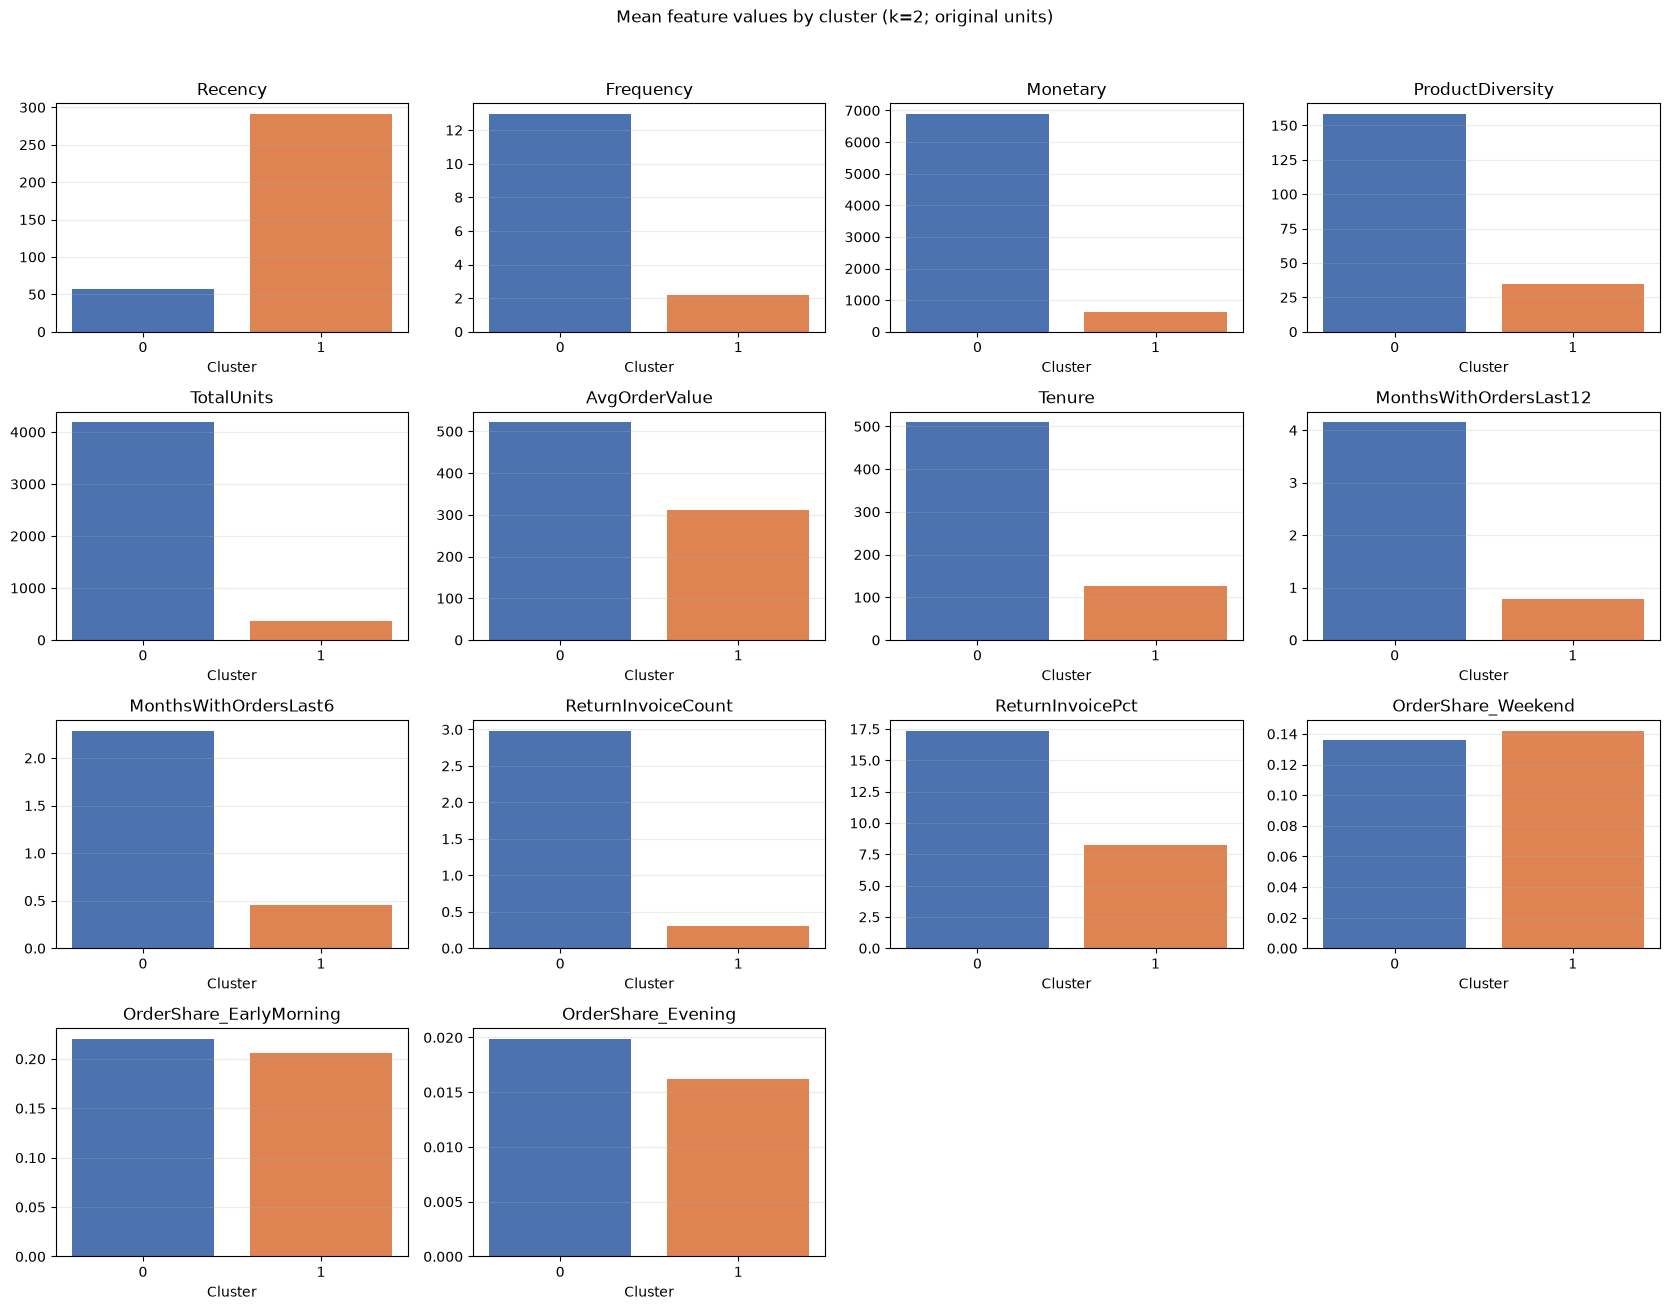

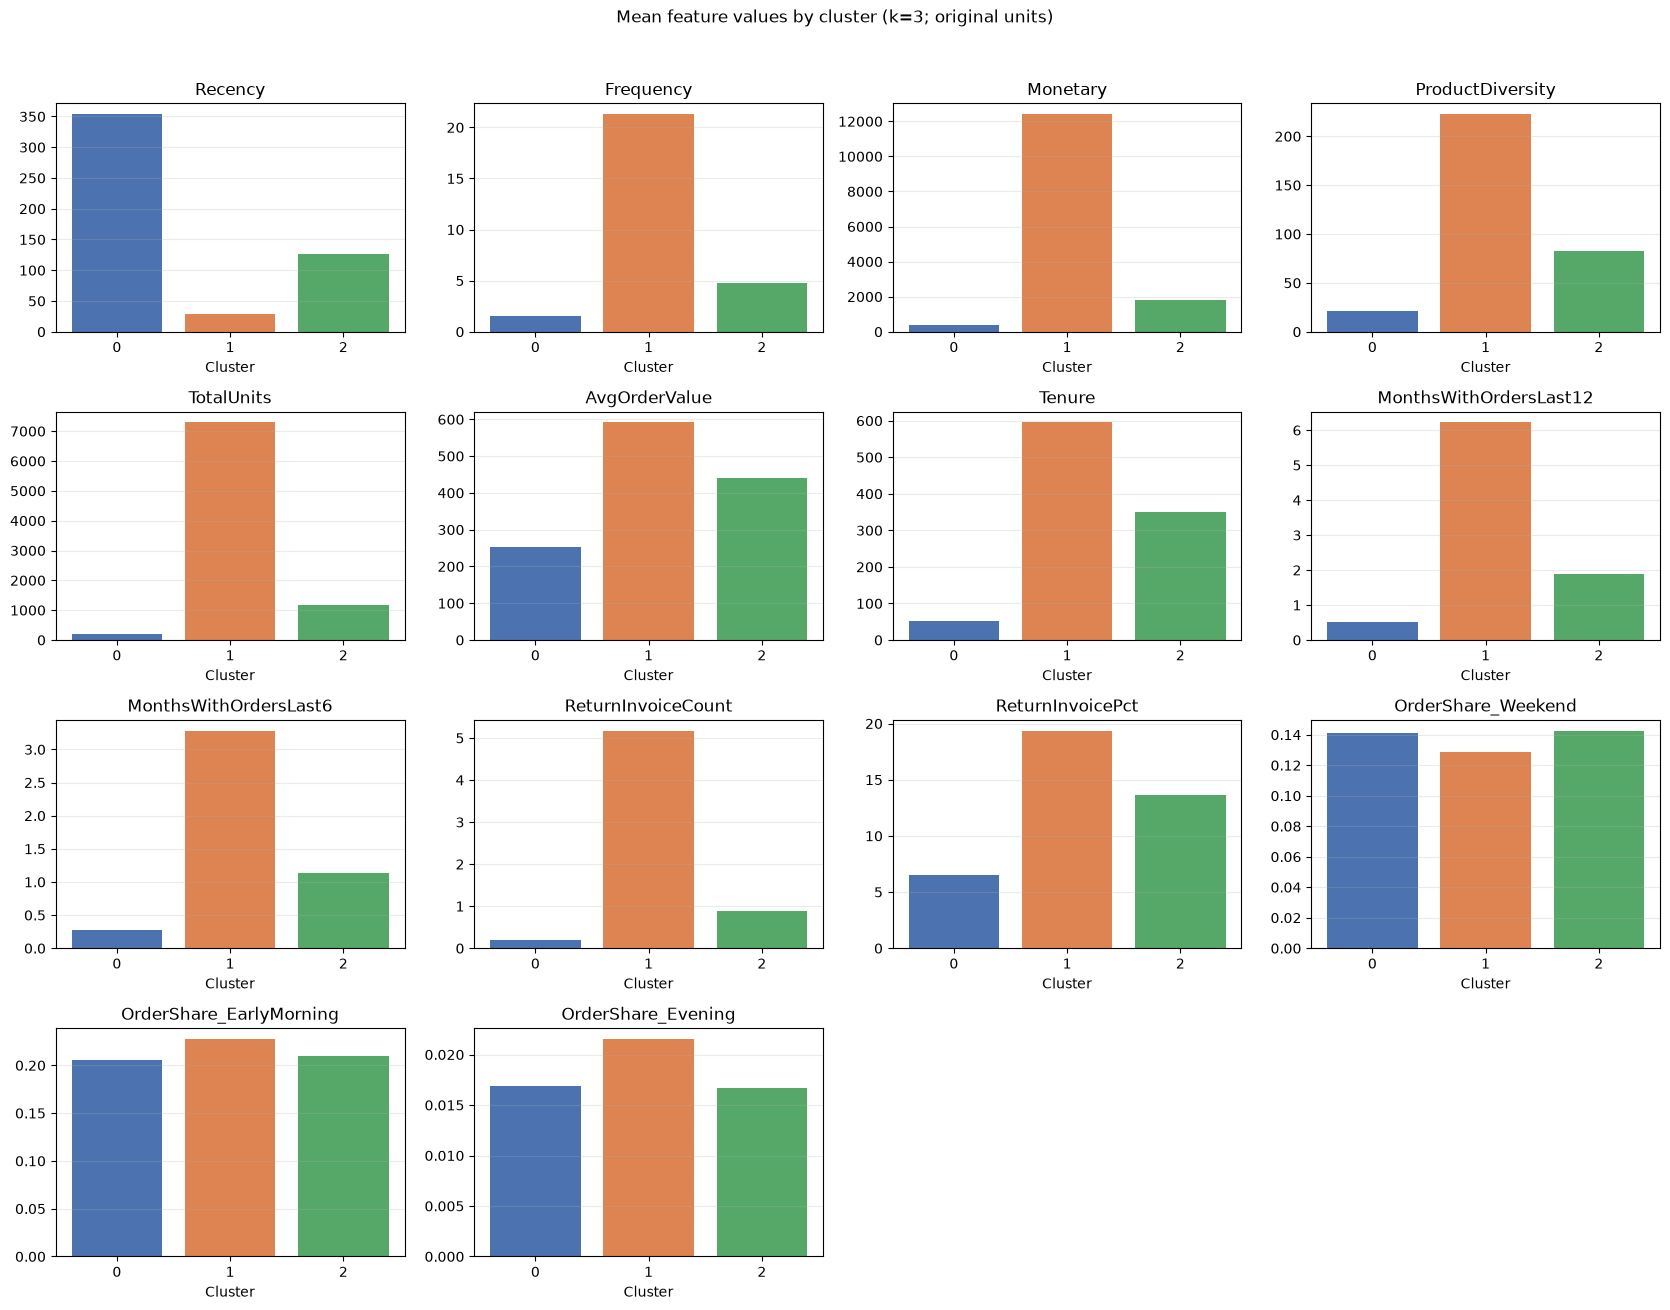

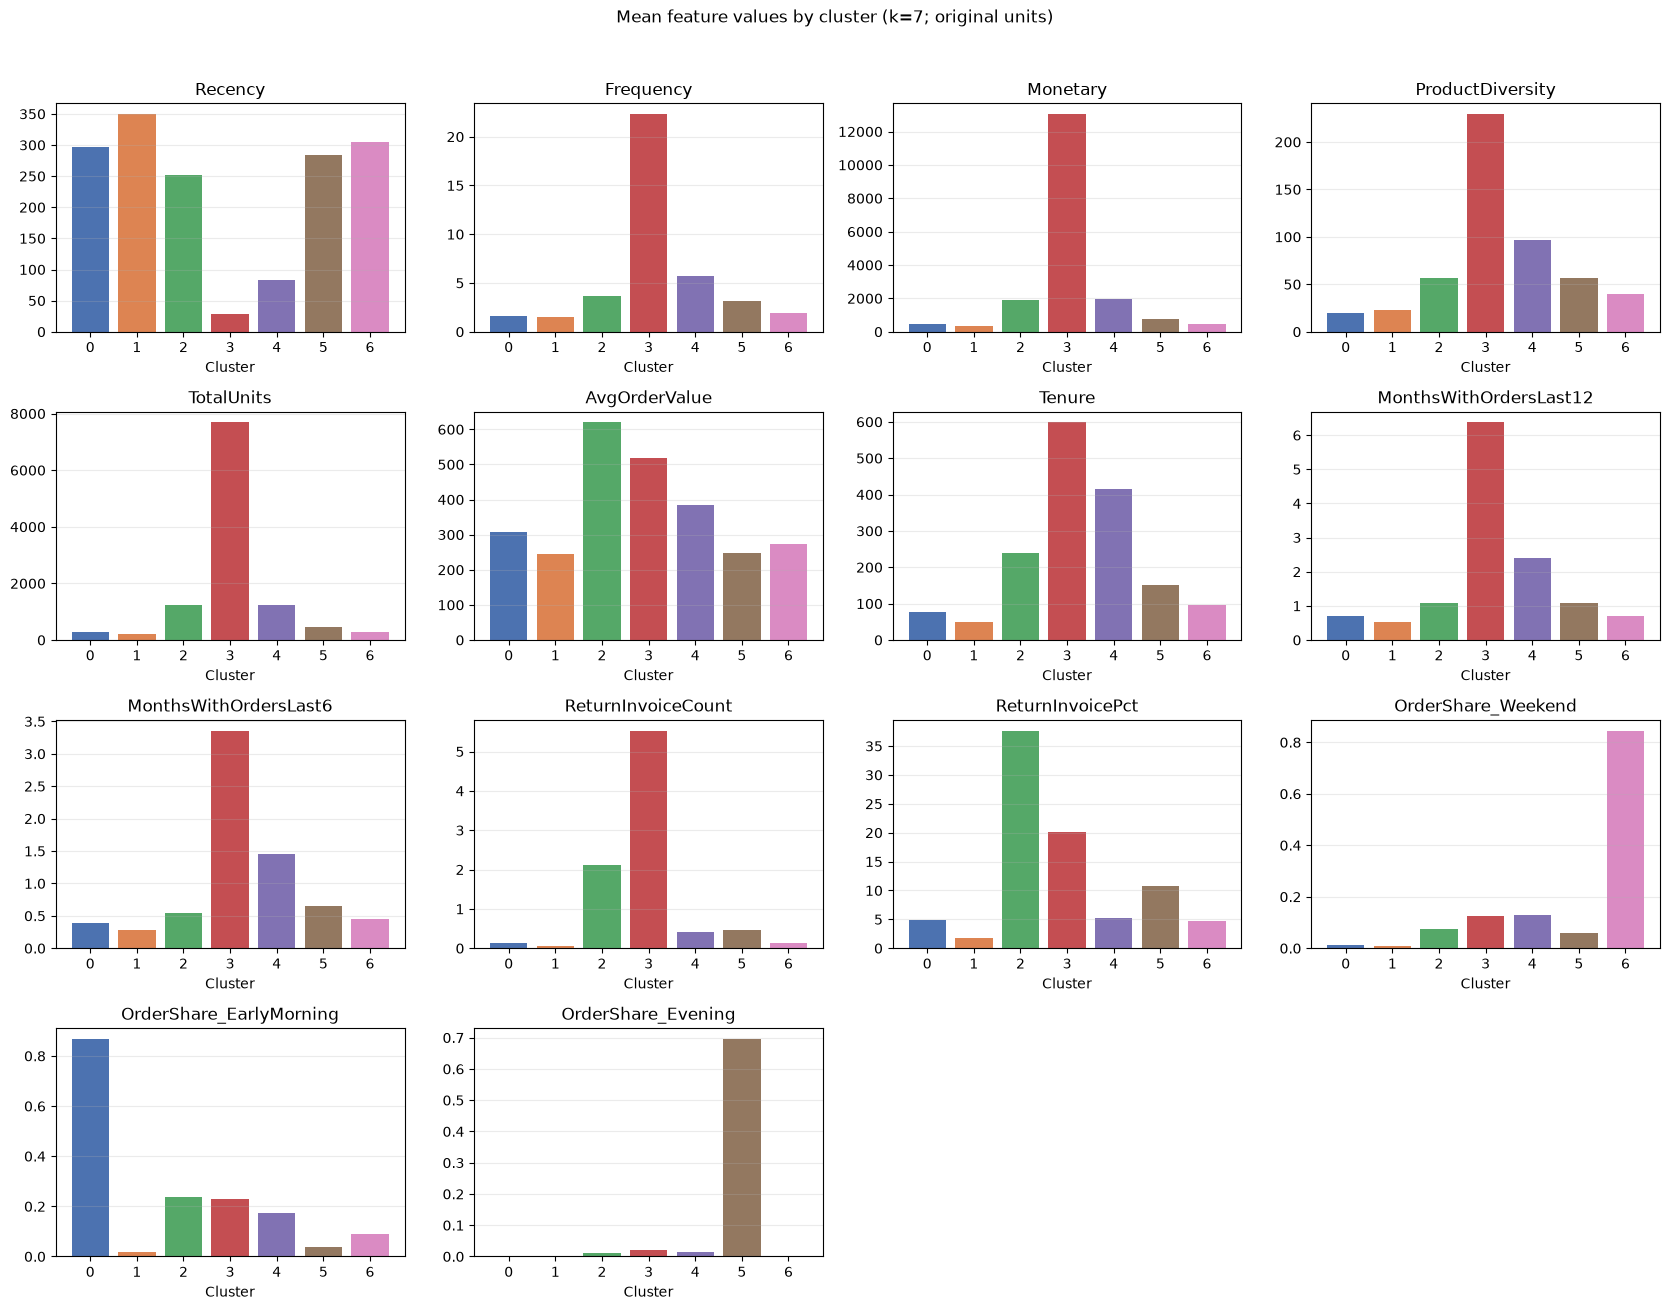

In [ ]:
# Plot each feature's mean in original units, with one chart per feature and k.
n_feature_cols = 4
n_feature_rows = int(np.ceil(len(profile_features.columns) / n_feature_cols))
cluster_palette = sns.color_palette("deep", 7)

for n_clusters in comparison_ks:
    mean_profiles = cluster_mean_profiles.loc[n_clusters]
    fig, axes = plt.subplots(
        n_feature_rows,
        n_feature_cols,
        figsize=(n_feature_cols * 4.2, n_feature_rows * 3.2),
        squeeze=False,
    )
    axes = axes.flatten()

    for ax, feature in zip(axes, profile_features.columns):
        cluster_values = mean_profiles[feature]
        ax.bar(
            cluster_values.index.astype(str),
            cluster_values.values,
            color=cluster_palette[:n_clusters],
        )
        ax.set_title(feature)
        ax.set_xlabel("Cluster")
        ax.grid(axis="y", alpha=0.25)
        ax.tick_params(axis="x", labelrotation=0)

    for ax in axes[len(profile_features.columns):]:
        ax.set_visible(False)

    fig.suptitle(f"Mean feature values by cluster (k={n_clusters}; original units)", y=1.02)
    fig.tight_layout()
    plt.show()


testing commit!!!!